<a href="https://colab.research.google.com/github/coque2000/BiLSTM_hypertension/blob/main/bilstm_cv_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BiLSTM para narrativas de pacientes hipertensos — Google Colab

Versión autocontenida de `trainers/bilstm_cv_trainer.py` (con `models/bilstm_model.py` y las utilidades que usa) para correr en Colab con GPU.

**Qué hace:** validación cruzada de 5 folds agrupada por paciente, BiLSTM con atención, líneas base (TF-IDF+LR y promedio de embedding+LR), ensamble de semillas, experimentos por dataset y pool (8b+14b+32b agrupados por paciente, evaluado en el test de cada dataset), y guarda todas las métricas, historiales por época, matrices, gráficas y logs en Google Drive.

## Antes de empezar
1. **Entorno con GPU:** *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU*.
2. **Sube a tu Google Drive** estos archivos, conservando la estructura del repositorio dentro de `MyDrive/FuncionesPLN/`:
   - `data/csv/narrativas_final/filtered/fixed/` → los 3 archivos `narrativas_deepseek-r1_{8b,14b,32b}_train_fixed_2026-02-20_00-01_filtrado.csv_fix.csv` (~10 MB cada uno)
   - `data/input/embeddings/SBW-vector/SBW-vectors-300-min5_narrativas.txt` (37 MB). Es la versión reducida de SBW con solo las palabras de tus narrativas; los vectores son idénticos al SBW completo. También funciona con el SBW completo (2.9 GB) si cambias `RUTA_SBW`.
3. Si usaste otra carpeta en Drive, cambia `RAIZ` en la celda 2.

## Cómo usarlo
- Ejecuta las celdas en orden. Solo se edita la celda **Configuración de la corrida** (`FASE`, `EMBEDDINGS`, etc.).
- **En paralelo:** abre este notebook en varias sesiones de Colab (por ejemplo, con cuentas distintas que compartan la carpeta de Drive) y en cada una pon un `NOMBRE_SESION` distinto y en `SOLO_EXPERIMENTOS` los experimentos que le tocan. Al final, junta todo con la celda **Consolidar corridas**.
- **Si Colab se desconecta:** vuelve a correr las celdas y pon en `REANUDAR_CORRIDA` la carpeta de la corrida. Continúa desde el último fold y semilla terminados, sin repetirlos.

## 1. GPU

In [1]:
# Verifica que la sesión tenga GPU (Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU)
import torch
print("torch", torch.__version__, "| CUDA disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("⚠ Sin GPU: el entrenamiento será muy lento. Cambia el tipo de entorno de ejecución a GPU.")

torch 2.11.0+cu130 | CUDA disponible: True
GPU: Tesla T4


## 2. Google Drive y archivos de datos

In [2]:
# Monta Google Drive y define la carpeta raíz del proyecto en Drive
from google.colab import drive
drive.mount("/content/drive")

import os
# Carpeta en Drive que replica la estructura del repositorio (cámbiala si la subiste a otro lugar)
RAIZ = "/content/drive/MyDrive/FuncionesPLN"

ARCHIVOS_NARRATIVAS = {
    "8b": "data/csv/narrativas_final/filtered/fixed/narrativas_deepseek-r1_8b_train_fixed_2026-02-20_00-01_filtrado.csv_fix.csv",
    "14b": "data/csv/narrativas_final/filtered/fixed/narrativas_deepseek-r1_14b_train_fixed_2026-02-20_00-01_filtrado.csv_fix.csv",
    "32b": "data/csv/narrativas_final/filtered/fixed/narrativas_deepseek-r1_32b_train_fixed_2026-02-20_00-01_filtrado.csv_fix.csv",
}
# Versión reducida de SBW (solo palabras de las narrativas, mismos vectores). También acepta el SBW completo.
RUTA_SBW = "data/input/embeddings/SBW-vector/SBW-vectors-300-min5_narrativas.txt"
# RUTA_SBW = "data/input/embeddings/SBW-vector/SBW-vectors-300-min5.txt"

for nombre, ruta in {**ARCHIVOS_NARRATIVAS, "SBW": RUTA_SBW}.items():
    completa = os.path.join(RAIZ, ruta)
    print(f"{'OK ' if os.path.exists(completa) else 'FALTA'} {nombre}: {completa}")

Mounted at /content/drive
OK  8b: /content/drive/MyDrive/FuncionesPLN/data/csv/narrativas_final/filtered/fixed/narrativas_deepseek-r1_8b_train_fixed_2026-02-20_00-01_filtrado.csv_fix.csv
OK  14b: /content/drive/MyDrive/FuncionesPLN/data/csv/narrativas_final/filtered/fixed/narrativas_deepseek-r1_14b_train_fixed_2026-02-20_00-01_filtrado.csv_fix.csv
OK  32b: /content/drive/MyDrive/FuncionesPLN/data/csv/narrativas_final/filtered/fixed/narrativas_deepseek-r1_32b_train_fixed_2026-02-20_00-01_filtrado.csv_fix.csv
OK  SBW: /content/drive/MyDrive/FuncionesPLN/data/input/embeddings/SBW-vector/SBW-vectors-300-min5_narrativas.txt


## 3. Librerías y logging

In [30]:
import datetime
import json
import logging as log
import os
import random
import re
import sys
from collections import Counter
from dataclasses import dataclass, field, asdict
from time import time
from typing import Optional

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader, Dataset

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

RAIZ_REPO = RAIZ  # las rutas relativas de la configuración se resuelven contra la carpeta de Drive

# Logging (equivalente a log/logger_base.py): consola; los archivos .log se agregan por corrida y experimento.
# force=True porque Colab ya trae un manejador configurado.
log.basicConfig(level=log.INFO, format="%(asctime)s: %(levelname)s %(message)s", datefmt="%Y-%m-%d %H:%M:%S",
                handlers=[log.StreamHandler(stream=sys.stdout)], force=True)

## 4. Utilidades del repositorio
`config_limpieza`, `NumpyEcoder`, `EarlyStopping`, `SpatialDropout`, carga del embedding y gráficas.

In [4]:
# ======================================================================================
# Código reutilizado del repositorio (copiado aquí para que el notebook sea autocontenido)
# ======================================================================================

# --- configuration/config_limpieza.py ---
PATRONES_OTROS_IDIOMAS = [
    r'[一-鿿]+',  # Chino   (Ideogramas)
    r'[぀-ゟ]+',  # Japonés (Hiragana)
    r'[゠-ヿ]+',  # Japonés (Katakana)
    r'[가-힯]+',  # Coreano (Hangul)
    r'[Ѐ-ӿ]+'   # Ruso    (Cirílico)
]


# --- utils/NumpyEcoder.py ---
class NumpyEncoder(json.JSONEncoder):
    """ Codificador personalizado para manejar tipos de NumPy """
    def default(self, obj):
        if isinstance(obj, (np.int64, np.int32)):
            return int(obj)
        if isinstance(obj, (np.float32, np.float64)):
            return float(obj)
        if isinstance(obj, np.ndarray):
            return obj.tolist()
        return super(NumpyEncoder, self).default(obj)


# --- trainers/engine.py (EarlyStopping) ---
class EarlyStopping:
    def __init__(self, patience=3, verbose=False, delta=0.01):
        self.patience = patience
        self.verbose = verbose
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.val_loss_min = np.inf
        self.delta = delta

    def __call__(self, val_loss, model, path):
        score = -val_loss
        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(val_loss, model, path)
        elif score < self.best_score + self.delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_checkpoint(val_loss, model, path)
            self.counter = 0

    def save_checkpoint(self, val_loss, model, path):
        torch.save(model.state_dict(), path)
        self.val_loss_min = val_loss


# --- models/cnn_bilstm_attention.py (SpatialDropout) ---
class SpatialDropout(nn.Module):
    def __init__(self, p=0.2):
        super().__init__()
        self.dropout2d = nn.Dropout2d(p)

    def forward(self, x):
        x = x.unsqueeze(2)  # (B, T, 1, D)
        x = self.dropout2d(x)
        return x.squeeze(2)


# --- utils/embeddings_utils.py (carga de embeddings y matriz) ---
class VectoresTexto:
    """Vectores leídos de un archivo de texto en formato word2vec (como KeyedVectors, pero sin gensim)."""

    def __init__(self, vectores: dict, dimension: int, tamano_archivo: int):
        self._v = vectores
        self.vector_size = dimension
        self.tamano_archivo = tamano_archivo

    def __contains__(self, palabra):
        return palabra in self._v

    def __getitem__(self, palabra):
        return self._v[palabra]

    def __len__(self):
        return len(self._v)


_CACHE_EMBEDDINGS = {}


def cargar_embedding(dir_embedding: str, palabras: Optional[set] = None):
    """
    Devuelve (modelo, dimension).
      - .txt / .vec (formato word2vec de texto, como SBW): se lee sin gensim. Si se da `palabras`, solo se
        guardan esos vectores (ahorra memoria con el SBW completo). Se guarda en caché entre experimentos.
      - .model / .kv / .bin: requiere gensim (!pip install gensim).
    """
    if not os.path.exists(dir_embedding):
        raise FileNotFoundError(f"No se encontró el archivo: {dir_embedding}")
    ext = os.path.splitext(dir_embedding)[1].lower()

    if ext in (".txt", ".vec"):
        en_cache = _CACHE_EMBEDDINGS.get(dir_embedding)
        if en_cache is not None and (palabras is None or palabras <= en_cache[0]):
            return en_cache[1], en_cache[1].vector_size
        log.info(f"Leyendo embedding {dir_embedding} ...")
        vectores = {}
        with open(dir_embedding, encoding="utf-8", errors="ignore") as f:
            n_total, dim = (int(x) for x in f.readline().split())
            for linea in f:
                partes = linea.rstrip().split(" ")
                if len(partes) != dim + 1:
                    continue
                if palabras is None or partes[0] in palabras:
                    vectores[partes[0]] = np.asarray(partes[1:], dtype=np.float32)
        modelo = VectoresTexto(vectores, dim, n_total)
        _CACHE_EMBEDDINGS[dir_embedding] = (set(palabras) if palabras is not None else set(vectores), modelo)
        log.info(f"Embedding cargado: {len(vectores)} vectores de {n_total} | dimensión {dim}")
        return modelo, dim

    from gensim.models import KeyedVectors, FastText
    if ext == ".bin":
        modelo = KeyedVectors.load_word2vec_format(dir_embedding, binary=True)
    else:
        try:
            modelo = KeyedVectors.load(dir_embedding)
        except Exception:
            modelo = FastText.load(dir_embedding)
    dim = modelo.vector_size if hasattr(modelo, "vector_size") else modelo.wv.vector_size
    return modelo, dim


def construir_matriz_embedding(word_index, modelo_w2v, dimension_embedding: int = 300):
    """Matriz para nn.Embedding: vector del embedding si existe; si no, aleatorio pequeño. Fila 0 = <pad>."""
    tam_vocabulario = len(word_index) + 1
    matrix_w2v = np.random.normal(scale=0.1, size=(tam_vocabulario, dimension_embedding))
    matrix_w2v[0] = np.zeros(dimension_embedding)
    vectors = modelo_w2v.wv if hasattr(modelo_w2v, "wv") else modelo_w2v
    hits = 0
    for palabra, i in word_index.items():
        if palabra in vectors:
            matrix_w2v[i] = vectors[palabra]
            hits += 1
    return torch.from_numpy(matrix_w2v).float()


# --- visualizers/grafica_entrenamiento.py ---
def graficar_entrenamiento(train_loss: list, val_loss: list, f1_macro_val: list,
                           f1_macro_test: list = None, nombre_archivo: str = "curva_entrenamiento",
                           dir_destino: str = "viewers", mostrar: bool = False):
    os.makedirs(dir_destino, exist_ok=True)
    epochs = range(1, len(train_loss) + 1)
    plt.figure(figsize=(14, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_loss, 'b-', label='Entrenamiento')
    plt.plot(epochs, val_loss, 'r-', label='Validación')
    plt.title('Curva de Pérdida (Loss)'); plt.xlabel('Épocas'); plt.ylabel('Loss'); plt.legend(); plt.grid(True)
    if len(f1_macro_val) > 0:
        plt.subplot(1, 2, 2)
        plt.plot(epochs, f1_macro_val, 'g-', label='F1-Macro (Val)')
        if f1_macro_test is not None and len(f1_macro_test) > 0:
            plt.plot(epochs[:len(f1_macro_test)], f1_macro_test, 'o--', color='orange', label='F1-Macro (Test)')
        plt.title('Rendimiento F1-Macro'); plt.xlabel('Épocas'); plt.ylabel('F1-Score'); plt.legend(); plt.grid(True)
    plt.tight_layout()
    plt.savefig(os.path.join(dir_destino, f"{nombre_archivo}.png"), dpi=300)
    plt.close()


# --- visualizers/matriz_confusion.py ---
def graficar_matriz_confusion(y_true, y_pred, clases: list[str], nombre_modelo: str,
                              mostrar: bool = False, dir_destino: str = "viewers"):
    import seaborn as sns
    os.makedirs(dir_destino, exist_ok=True)
    cm = confusion_matrix(y_true, y_pred, labels=clases)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=clases, yticklabels=clases)
    plt.title(f'Matriz de Confusión: {nombre_modelo}'); plt.ylabel('Clase Real'); plt.xlabel('Clase Predicha')
    plt.savefig(os.path.join(dir_destino, f"matriz_{nombre_modelo}.png"), dpi=300, bbox_inches='tight')
    plt.clf(); plt.close('all')

## 5. Modelo `BiLSTM_AtencionMascara`

In [5]:
# --- models/bilstm_model.py: BiLSTM_AtencionMascara ---
class BiLSTM_AtencionMascara(nn.Module):
    def __init__(self, vocab_size: int, embedding_dim: int, hidden_dim: int, output_dim: int,
                 weights_matrix=None, congelar_embedding: bool = True, dropout: float = 0.4,
                 dropout_embedding: float = 0.2, num_capas: int = 1):
        super().__init__()

        if weights_matrix is not None:
            weights_matrix = torch.as_tensor(weights_matrix, dtype=torch.float).clone()
            weights_matrix[0] = 0.0  # El vector de <pad> siempre en ceros
            self.embedding = nn.Embedding.from_pretrained(weights_matrix, freeze=congelar_embedding,
                                                          padding_idx=0)
        else:
            self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)

        self.dropout_embedding = SpatialDropout(dropout_embedding)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, num_layers=num_capas, batch_first=True,
                            bidirectional=True, dropout=dropout if num_capas > 1 else 0.0)
        self.atencion = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, 1, bias=False)
        )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim * 4, output_dim)
        self.ultimos_pesos_atencion = None

    def congelar_embedding(self, congelar: bool):
        self.embedding.weight.requires_grad = not congelar

    def forward(self, x: torch.Tensor, longitudes: torch.Tensor) -> torch.Tensor:
        mascara = x != 0
        emb = self.dropout_embedding(self.embedding(x))
        empaquetado = pack_padded_sequence(emb, longitudes.cpu(), batch_first=True, enforce_sorted=False)
        salida_emp, _ = self.lstm(empaquetado)
        salida, _ = pad_packed_sequence(salida_emp, batch_first=True, total_length=x.size(1))

        puntajes = self.atencion(salida).squeeze(-1)
        puntajes = puntajes.masked_fill(~mascara, float("-inf"))
        pesos = torch.softmax(puntajes, dim=1)
        self.ultimos_pesos_atencion = pesos.detach()
        contexto_atencion = torch.bmm(pesos.unsqueeze(1), salida).squeeze(1)
        contexto_max = salida.masked_fill(~mascara.unsqueeze(-1), float("-inf")).max(dim=1).values

        representacion = torch.cat([contexto_atencion, contexto_max], dim=1)
        return self.fc(self.dropout(representacion))

## 6. Entrenador (`bilstm_cv_trainer.py`)
Configuración, datos, folds por paciente, entrenamiento, líneas base, métricas, JSON, gráficas y reanudación.

In [6]:
PAD, UNK, NUM = "<pad>", "<unk>", "<num>"


# ======================================================================================
# Configuración
# ======================================================================================
@dataclass
class ConfigBiLSTM:
    nombre_experimento: str = "bilstm"

    # --- Datos ---
    # Archivos por modelo generador. Deben compartir los mismos IDs de paciente.
    archivos_por_modelo: dict = field(default_factory=lambda: dict(ARCHIVOS_NARRATIVAS))
    # Atajo para una corrida con un solo dataset: dataset="8b" equivale a entrenar, validar y probar con 8b.
    # Déjalo en None para usar los campos de abajo.
    dataset: Optional[str] = None
    modelos_entrenamiento: list = field(default_factory=lambda: ["32b"])  # p. ej. ["8b", "14b", "32b"] = pool
    modelo_evaluacion: str = "32b"  # dataset de validación y test si no se indican las listas de abajo
    # Listas opcionales (None = [modelo_evaluacion]). En el pool se usan los tres datasets: la validación junta
    # las narrativas de los pacientes de validación de los tres, y el test se evalúa por separado en cada uno.
    modelos_validacion: Optional[list] = None
    modelos_test: Optional[list] = None
    col_id: str = "0"
    col_texto: str = "2"
    col_clase: str = "5"
    descartar_otros_idiomas: bool = False  # True = elimina la narrativa completa si tiene chino/cirílico

    # --- Texto ---
    normalizar_numeros: bool = True  # 153/84 -> <num> <num>
    min_freq: int = 2  # frecuencia mínima en el train del fold para entrar al vocabulario
    max_len: Optional[int] = None  # None = percentil del train
    percentil_longitud: int = 95
    max_len_tope: int = 1000
    proporcion_cabeza: float = 0.25  # al truncar: 25 % inicio + 75 % final

    # --- Embedding ---
    ruta_embedding: Optional[str] = None  # None = embedding aleatorio entrenable
    embedding_dim: int = 300  # solo se usa si ruta_embedding es None
    congelar_embedding: bool = True
    descongelar_en_epoca: Optional[int] = None  # p. ej. 5 para ajustar el embedding después
    lr_embedding: float = 1e-4

    # --- Modelo ---
    hidden_dim: int = 128
    num_capas: int = 1
    dropout: float = 0.4
    dropout_embedding: float = 0.2

    # --- Entrenamiento ---
    lr: float = 1e-3
    weight_decay: float = 1e-4
    batch_size: int = 32
    epocas_max: int = 40
    paciencia: int = 6  # épocas sin mejorar el F1 de validación antes de detenerse
    epocas_minimas: int = 0  # el early stopping no puede detener el run antes de esta época
    recorte_gradiente: float = 1.0
    # Planificador ReduceLROnPlateau: si el F1 de validación no mejora en paciencia_planificador épocas,
    # el lr se multiplica por factor_planificador, sin bajar de lr_minimo
    paciencia_planificador: int = 2
    factor_planificador: float = 0.5
    lr_minimo: float = 0.0
    hilos_cpu: Optional[int] = None  # None = lo que decida PyTorch; p. ej. 8 para usar todos los hilos lógicos
    pesos_clase: bool = True
    evaluar_train_cada_epoca: bool = True  # F1/accuracy de train por época (sin dropout)

    # --- Protocolo ---
    n_folds: int = 5
    semilla_particion: int = 42
    semillas: list = field(default_factory=lambda: [13, 42, 77])
    proporcion_val: float = 0.1  # del train de cada fold, agrupado por paciente

    # --- Líneas base ---
    baseline_tfidf: bool = True
    baseline_promedio_embedding: bool = True

    # --- Salida ---
    dir_destino: str = os.path.join("data", "output", "bilstm_cv")
    guardar_graficas: bool = True
    variante: Optional[str] = None  # nombre de la variante de embedding (lo llena construir_experimentos)

    def __post_init__(self):
        if self.dataset is not None:
            self.modelos_entrenamiento = [self.dataset]
            self.modelo_evaluacion = self.dataset
            self.modelos_validacion = [self.dataset]
            self.modelos_test = [self.dataset]
        if self.modelos_validacion is None:
            self.modelos_validacion = [self.modelo_evaluacion]
        if self.modelos_test is None:
            self.modelos_test = [self.modelo_evaluacion]
        usados = set(self.modelos_entrenamiento) | set(self.modelos_validacion) | set(self.modelos_test)
        desconocidos = usados - set(self.archivos_por_modelo)
        if desconocidos:
            raise ValueError(f"Datasets sin archivo en archivos_por_modelo: {desconocidos}")

    @property
    def es_pool(self) -> bool:
        return len(self.modelos_entrenamiento) > 1

    @property
    def modelos_usados(self) -> list:
        return sorted(set(self.modelos_entrenamiento) | set(self.modelos_validacion) | set(self.modelos_test))


# ======================================================================================
# Datos
# ======================================================================================
_PATRON_OTROS_IDIOMAS = re.compile("|".join(PATRONES_OTROS_IDIOMAS))
_PATRON_TOKEN = re.compile(r"[a-záéíóúüñ]+|\d+(?:[.,]\d+)?")


def normalizar_etiqueta(valor) -> str:
    if pd.isna(valor):
        return "sin_evento"
    valor = str(valor).strip().lower()
    return "sin_evento" if valor in {"null", "nan", "none", ""} else valor


def cargar_narrativas(cfg: ConfigBiLSTM) -> pd.DataFrame:
    """Une las narrativas de los modelos pedidos en un solo DataFrame: id, texto, clase, modelo."""
    modelos = cfg.modelos_usados
    partes = []
    for modelo in modelos:
        ruta = cfg.archivos_por_modelo[modelo]
        if not os.path.isabs(ruta):
            ruta = os.path.join(RAIZ_REPO, ruta)
        df = pd.read_csv(ruta, encoding="utf-8", usecols=[cfg.col_id, cfg.col_texto, cfg.col_clase])
        df.columns = ["id", "texto", "clase"]
        df["clase"] = df["clase"].map(normalizar_etiqueta)
        df["modelo"] = modelo
        antes = len(df)
        df = df.dropna(subset=["texto"])
        df = df[df["texto"].astype(str).str.strip() != ""]
        if cfg.descartar_otros_idiomas:
            df = df[~df["texto"].str.contains(_PATRON_OTROS_IDIOMAS)]
        log.info(f"[{modelo}] {len(df)}/{antes} narrativas | {df['clase'].value_counts().to_dict()}")
        partes.append(df)
    datos = pd.concat(partes, ignore_index=True)
    datos["id"] = datos["id"].astype(str)

    # Una etiqueta por paciente: si no, la agrupación no tendría sentido
    inconsistentes = datos.groupby("id")["clase"].nunique()
    inconsistentes = inconsistentes[inconsistentes > 1]
    if len(inconsistentes):
        raise ValueError(f"{len(inconsistentes)} pacientes con etiquetas distintas entre modelos, "
                         f"ej.: {inconsistentes.index[:5].tolist()}")
    return datos


def tokenizar(texto: str, normalizar_numeros: bool = True) -> list[str]:
    """Minúsculas, sin otros idiomas ni puntuación. Conserva stopwords (no, sin, muy...)."""
    texto = _PATRON_OTROS_IDIOMAS.sub(" ", str(texto).lower())
    tokens = _PATRON_TOKEN.findall(texto)
    if normalizar_numeros:
        tokens = [NUM if t[0].isdigit() else t for t in tokens]
    return tokens


class Vocabulario:
    def __init__(self, textos_train: list[list[str]], min_freq: int = 2, palabras_extra: set = None):
        """
        textos_train: textos tokenizados del train del fold (lo único que define la frecuencia).
        palabras_extra: palabras que se agregan aunque no lleguen a min_freq porque el embedding
                        preentrenado sí las conoce (no usa etiquetas, así que no hay fuga).
        """
        frecuencias = Counter(t for tokens in textos_train for t in tokens)
        palabras = {p for p, f in frecuencias.items() if f >= min_freq}
        if palabras_extra:
            palabras |= palabras_extra
        palabras.discard(PAD)
        palabras.discard(UNK)
        self.itos = [PAD, UNK] + sorted(palabras)
        self.stoi = {p: i for i, p in enumerate(self.itos)}

    def __len__(self):
        return len(self.itos)

    def codificar(self, tokens: list[str]) -> list[int]:
        unk = self.stoi[UNK]
        return [self.stoi.get(t, unk) for t in tokens]

    @property
    def word_index(self) -> dict:
        """Formato que espera construir_matriz_embedding (índices desde 1; 0 = <pad>)."""
        return {p: i for i, p in enumerate(self.itos) if i > 0}


def truncar_cabeza_cola(ids: list[int], max_len: int, proporcion_cabeza: float) -> list[int]:
    if len(ids) <= max_len:
        return ids
    n_cabeza = int(max_len * proporcion_cabeza)
    n_cola = max_len - n_cabeza
    return ids[:n_cabeza] + ids[-n_cola:]


class SecuenciasDataset(Dataset):
    def __init__(self, secuencias: list[list[int]], etiquetas: np.ndarray):
        self.secuencias = [torch.tensor(s if len(s) else [1], dtype=torch.long) for s in secuencias]
        self.etiquetas = torch.tensor(etiquetas, dtype=torch.long)

    def __len__(self):
        return len(self.etiquetas)

    def __getitem__(self, idx):
        return self.secuencias[idx], self.etiquetas[idx]


def collate_relleno(lote):
    """Padding dinámico al máximo del lote (no al máximo global)."""
    secuencias, etiquetas = zip(*lote)
    longitudes = torch.tensor([len(s) for s in secuencias], dtype=torch.long)
    x = nn.utils.rnn.pad_sequence(secuencias, batch_first=True, padding_value=0)
    return x, longitudes, torch.stack(etiquetas)


def cargar_pacientes(cfg: ConfigBiLSTM) -> pd.DataFrame:
    """
    Lista de pacientes (id, clase) tomada de TODOS los archivos de archivos_por_modelo, aunque el
    experimento solo use uno. Así los folds no dependen de qué datasets se cargan.
    """
    partes = []
    for ruta in cfg.archivos_por_modelo.values():
        if not os.path.isabs(ruta):
            ruta = os.path.join(RAIZ_REPO, ruta)
        if not os.path.exists(ruta):
            log.warning(f"No existe {ruta}; sus pacientes no se usan para definir los folds")
            continue
        df = pd.read_csv(ruta, encoding="utf-8", usecols=[cfg.col_id, cfg.col_clase])
        df.columns = ["id", "clase"]
        partes.append(df)
    pacientes = pd.concat(partes, ignore_index=True)
    pacientes["id"] = pacientes["id"].astype(str)
    pacientes["clase"] = pacientes["clase"].map(normalizar_etiqueta)
    return pacientes.drop_duplicates("id")


def crear_particiones(pacientes: pd.DataFrame, cfg: ConfigBiLSTM) -> pd.DataFrame:
    """
    Asigna un fold a cada paciente. Como la lista de pacientes es la misma para todos los experimentos,
    un paciente cae en el mismo fold en las corridas 8b, 14b, 32b y 8b+14b+32b, y los resultados se
    pueden comparar fold a fold. Devuelve DataFrame id, clase, fold.
    """
    pacientes = pacientes[["id", "clase"]].sort_values("id").reset_index(drop=True)
    pacientes["fold"] = -1
    sgkf = StratifiedGroupKFold(n_splits=cfg.n_folds, shuffle=True, random_state=cfg.semilla_particion)
    for k, (_, idx_test) in enumerate(sgkf.split(pacientes, pacientes["clase"], groups=pacientes["id"])):
        pacientes.loc[idx_test, "fold"] = k
    return pacientes


def separar_validacion(ids_train: np.ndarray, clases_train: np.ndarray, cfg: ConfigBiLSTM, semilla: int):
    n_partes = max(2, round(1 / cfg.proporcion_val))
    sgkf = StratifiedGroupKFold(n_splits=n_partes, shuffle=True, random_state=semilla)
    idx_tr, idx_val = next(sgkf.split(ids_train, clases_train, groups=ids_train))
    return set(ids_train[idx_tr]), set(ids_train[idx_val])


# ======================================================================================
# Entrenamiento
# ======================================================================================
def fijar_semilla(semilla: int):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.cuda.manual_seed_all(semilla)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def entrenar_una_epoca(modelo, loader, criterio, optimizador, device, recorte: float) -> float:
    modelo.train()
    perdida_total = 0.0
    for x, longitudes, y in loader:
        x, y = x.to(device), y.to(device)
        optimizador.zero_grad()
        perdida = criterio(modelo(x, longitudes), y)
        perdida.backward()
        if recorte:
            nn.utils.clip_grad_norm_(modelo.parameters(), recorte)
        optimizador.step()
        perdida_total += perdida.item() * len(y)
    return perdida_total / len(loader.dataset)


@torch.no_grad()
def evaluar(modelo, loader, criterio, device):
    """Devuelve loss, F1 macro, accuracy, y_true, y_pred y probabilidades por clase (softmax)."""
    modelo.eval()
    perdida_total, y_true, y_pred, probs = 0.0, [], [], []
    for x, longitudes, y in loader:
        x, y = x.to(device), y.to(device)
        logits = modelo(x, longitudes)
        perdida_total += criterio(logits, y).item() * len(y)
        y_true.extend(y.cpu().tolist())
        y_pred.extend(logits.argmax(dim=1).cpu().tolist())
        probs.append(torch.softmax(logits, dim=1).cpu().numpy())
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    acc = accuracy_score(y_true, y_pred)
    return perdida_total / len(loader.dataset), f1, acc, y_true, y_pred, np.concatenate(probs)


def contar_parametros(modelo) -> dict:
    return {"total": sum(p.numel() for p in modelo.parameters()),
            "entrenables": sum(p.numel() for p in modelo.parameters() if p.requires_grad),
            "embedding": sum(p.numel() for p in modelo.embedding.parameters())}


def entrenar_bilstm(cfg: ConfigBiLSTM, vocab: Vocabulario, matriz_embedding, num_clases: int,
                    ds_train, ds_val, ds_tests: dict, y_train: np.ndarray, device, ruta_checkpoint: str,
                    semilla: int):
    """
    Entrena una BiLSTM y devuelve un dict con:
      epocas: lista con las métricas de cada época
      mejor_epoca, epoca_early_stopping, epocas_ejecutadas, f1_val_mejor
      parametros: conteo de parámetros (al inicio y, si aplica, tras descongelar el embedding)
      test: {dataset: {"y_true", "y_pred", "probs"}} con el mejor checkpoint, uno por cada conjunto de test
    ds_tests: {dataset: SecuenciasDataset}. Con un solo dataset es {"32b": ...}; en el pool, uno por dataset.
    """
    fijar_semilla(semilla)
    gen = torch.Generator().manual_seed(semilla)
    loader_train = DataLoader(ds_train, batch_size=cfg.batch_size, shuffle=True, collate_fn=collate_relleno,
                              generator=gen)
    # Mismo train sin barajar, para medir F1/accuracy de train en modo evaluación (sin dropout)
    loader_train_eval = DataLoader(ds_train, batch_size=cfg.batch_size * 2, shuffle=False,
                                   collate_fn=collate_relleno)
    loader_val = DataLoader(ds_val, batch_size=cfg.batch_size * 2, shuffle=False, collate_fn=collate_relleno)
    loaders_test = {nombre: DataLoader(ds, batch_size=cfg.batch_size * 2, shuffle=False, collate_fn=collate_relleno)
                    for nombre, ds in ds_tests.items()}

    dim = matriz_embedding.shape[1] if matriz_embedding is not None else cfg.embedding_dim
    modelo = BiLSTM_AtencionMascara(
        vocab_size=len(vocab), embedding_dim=dim, hidden_dim=cfg.hidden_dim, output_dim=num_clases,
        weights_matrix=matriz_embedding,
        congelar_embedding=cfg.congelar_embedding if matriz_embedding is not None else False,
        dropout=cfg.dropout, dropout_embedding=cfg.dropout_embedding, num_capas=cfg.num_capas
    ).to(device)
    parametros = {"inicio": contar_parametros(modelo)}

    pesos = None
    if cfg.pesos_clase:
        pesos = compute_class_weight("balanced", classes=np.arange(num_clases), y=y_train)
        pesos = torch.tensor(pesos, dtype=torch.float, device=device)
    criterio = nn.CrossEntropyLoss(weight=pesos)

    # El embedding tiene su propio lr; si está congelado sus gradientes son None y AdamW lo ignora
    params_embedding = list(modelo.embedding.parameters())
    ids_embedding = {id(p) for p in params_embedding}
    params_resto = [p for p in modelo.parameters() if id(p) not in ids_embedding]
    lr_emb = cfg.lr_embedding if matriz_embedding is not None else cfg.lr
    optimizador = torch.optim.AdamW([
        {"params": params_resto, "lr": cfg.lr},
        {"params": params_embedding, "lr": lr_emb, "weight_decay": 0.0},
    ], weight_decay=cfg.weight_decay)
    planificador = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizador, mode="max", factor=cfg.factor_planificador,
                                                              patience=cfg.paciencia_planificador,
                                                              min_lr=cfg.lr_minimo)

    # EarlyStopping de trainers/engine.py minimiza "val_loss"; le pasamos -F1 para maximizar F1
    early_stop = EarlyStopping(patience=cfg.paciencia, delta=1e-3)

    epocas, epoca_early_stopping = [], None
    for epoca in range(1, cfg.epocas_max + 1):
        t0 = time()
        if (cfg.descongelar_en_epoca is not None and matriz_embedding is not None
                and epoca == cfg.descongelar_en_epoca):
            modelo.congelar_embedding(False)
            parametros[f"tras_descongelar_ep{epoca}"] = contar_parametros(modelo)
            log.info(f"    Época {epoca}: embedding descongelado (lr={lr_emb})")

        # lr con el que se entrena ESTA época (antes de que el planificador lo modifique)
        lr_actual = optimizador.param_groups[0]["lr"]
        lr_emb_actual = optimizador.param_groups[1]["lr"]
        embedding_entrenable = modelo.embedding.weight.requires_grad

        perdida_train = entrenar_una_epoca(modelo, loader_train, criterio, optimizador, device,
                                           cfg.recorte_gradiente)
        t_entrenamiento = time() - t0

        f1_train = acc_train = perdida_train_eval = None
        if cfg.evaluar_train_cada_epoca:
            perdida_train_eval, f1_train, acc_train, _, _, _ = evaluar(modelo, loader_train_eval, criterio, device)
        perdida_val, f1_val, acc_val, _, _, _ = evaluar(modelo, loader_val, criterio, device)
        planificador.step(f1_val)

        mejoro = early_stop.best_score is None or f1_val >= early_stop.best_score + early_stop.delta
        early_stop(-f1_val, modelo, ruta_checkpoint)

        epocas.append({
            "epoca": epoca,
            "train_loss": perdida_train,  # promedio durante el entrenamiento (con dropout)
            "train_loss_eval": perdida_train_eval,  # train evaluado sin dropout al final de la época
            "train_f1": f1_train,
            "train_accuracy": acc_train,
            "val_loss": perdida_val,
            "val_f1": f1_val,
            "val_accuracy": acc_val,
            "lr": lr_actual,
            "lr_embedding": lr_emb_actual,
            "embedding_entrenable": embedding_entrenable,
            "mejor_hasta_ahora": mejoro,
            "contador_early_stopping": early_stop.counter,
            "segundos_entrenamiento": t_entrenamiento,
            "segundos_total": time() - t0,
        })
        f1_train_txt = f"{f1_train:.4f}" if f1_train is not None else "-"
        log.info(f"    Época {epoca:02d} | train_loss {perdida_train:.4f} f1 {f1_train_txt} | "
              f"val_loss {perdida_val:.4f} f1 {f1_val:.4f} | lr {lr_actual:.1e} | {time() - t0:.1f}s")

        # Se detiene tras `paciencia` épocas sin mejora, pero nunca antes de `epocas_minimas`.
        # (Se usa el contador y no la bandera early_stop, porque la bandera no se reinicia si luego mejora.)
        if early_stop.counter >= cfg.paciencia and epoca >= cfg.epocas_minimas:
            epoca_early_stopping = epoca
            log.info(f"    Early stopping en la época {epoca}")
            break

    # Recuperar el mejor checkpoint (mejor F1 de validación) y evaluar en cada conjunto de test
    modelo.load_state_dict(torch.load(ruta_checkpoint, map_location=device))
    _, f1_val_mejor, _, _, _, _ = evaluar(modelo, loader_val, criterio, device)
    test = {}
    for nombre, loader in loaders_test.items():
        _, _, _, y_true, y_pred, probs = evaluar(modelo, loader, criterio, device)
        test[nombre] = {"y_true": y_true, "y_pred": y_pred, "probs": probs}
    epocas_guardadas = [e["epoca"] for e in epocas if e["mejor_hasta_ahora"]]
    return {
        "epocas": epocas,
        "mejor_epoca": epocas_guardadas[-1] if epocas_guardadas else int(np.argmax([e["val_f1"] for e in epocas])) + 1,
        "epoca_early_stopping": epoca_early_stopping,
        "epocas_ejecutadas": len(epocas),
        "f1_val_mejor": f1_val_mejor,
        "parametros": parametros,
        "test": test,
    }


# ======================================================================================
# Líneas base (mismos folds)
# ======================================================================================
def baseline_tfidf_lr(textos_train, y_train, textos_test: dict) -> dict:
    """textos_test: {dataset: textos}. Devuelve {dataset: (predicciones, probabilidades)}."""
    vectorizador = TfidfVectorizer(min_df=2, sublinear_tf=True, lowercase=False,
                                   tokenizer=str.split, token_pattern=None)
    x_train = vectorizador.fit_transform(textos_train)
    clf = LogisticRegression(C=10, max_iter=5000, class_weight="balanced")
    clf.fit(x_train, y_train)
    salida = {}
    for n, textos in textos_test.items():
        x_test = vectorizador.transform(textos)
        salida[n] = (clf.predict(x_test), clf.predict_proba(x_test))
    return salida


def promedio_embeddings(secuencias: list[list[int]], matriz: np.ndarray) -> np.ndarray:
    salida = np.zeros((len(secuencias), matriz.shape[1]), dtype=np.float32)
    for i, s in enumerate(secuencias):
        validos = [t for t in s if t > 1]  # sin <pad> ni <unk>
        if validos:
            salida[i] = matriz[validos].mean(axis=0)
    return salida


def baseline_promedio_lr(sec_train, y_train, secs_test: dict, matriz) -> dict:
    """secs_test: {dataset: secuencias}. Devuelve {dataset: (predicciones, probabilidades)}."""
    clf = LogisticRegression(C=1.0, max_iter=5000, class_weight="balanced")
    clf.fit(promedio_embeddings(sec_train, matriz), y_train)
    salida = {}
    for n, secs in secs_test.items():
        x_test = promedio_embeddings(secs, matriz)
        salida[n] = (clf.predict(x_test), clf.predict_proba(x_test))
    return salida


def ensamble_semillas(df_pred: pd.DataFrame, nombres_clases: list[str]) -> pd.DataFrame:
    """
    Ensamble de semillas: para cada paciente de test (y cada conjunto de test), promedia las probabilidades
    que dieron las distintas semillas y toma la clase de mayor probabilidad promedio.
    Devuelve filas con modelo="bilstm_ensamble" y semilla="ensamble", en el mismo formato que predicciones.csv.
    """
    cols_prob = [f"prob_{c}" for c in nombres_clases]
    g = df_pred.groupby(["datos_test", "fold", "id"])
    ens = g[cols_prob].mean()
    ens["clase_real"] = g["clase_real"].first()
    ens = ens.reset_index()
    ens["clase_predicha"] = [nombres_clases[i] for i in ens[cols_prob].to_numpy().argmax(axis=1)]
    ens["correcto"] = ens["clase_real"] == ens["clase_predicha"]
    ens["prob_predicha"] = ens[cols_prob].max(axis=1)
    ens["modelo"] = "bilstm_ensamble"
    ens["semilla"] = "ensamble"
    return ens[["modelo", "datos_test", "id", "fold", "semilla", "clase_real", "clase_predicha", "correcto"]
               + cols_prob + ["prob_predicha"]]


# ======================================================================================
# Métricas, JSON y gráficas
# ======================================================================================
class NumpyEncoderExtendido(NumpyEncoder):
    """NumpyEncoder de utils/NumpyEcoder.py + enteros/flotantes/bool de NumPy de cualquier tamaño."""

    def default(self, obj):
        if isinstance(obj, np.integer):
            return int(obj)
        if isinstance(obj, np.floating):
            return float(obj)
        if isinstance(obj, np.bool_):
            return bool(obj)
        return super().default(obj)


def _sin_nan(obj):
    """Convierte NaN/inf en None para que el JSON sea estándar (legible desde cualquier lenguaje)."""
    if isinstance(obj, dict):
        return {str(k): _sin_nan(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_sin_nan(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return _sin_nan(obj.tolist())
    if isinstance(obj, (float, np.floating)) and not np.isfinite(obj):
        return None
    return obj


def guardar_json(datos, ruta: str):
    with open(ruta, "w", encoding="utf-8") as f:
        json.dump(_sin_nan(datos), f, indent=2, ensure_ascii=False, cls=NumpyEncoderExtendido)


def reporte_clasificacion(y_true, y_pred, nombres_clases) -> dict:
    return classification_report(y_true, y_pred, labels=list(range(len(nombres_clases))),
                                 target_names=nombres_clases, output_dict=True, zero_division=0)


def matriz_confusion(y_true, y_pred, num_clases: int) -> np.ndarray:
    return confusion_matrix(y_true, y_pred, labels=list(range(num_clases)))


def fila_metricas(y_true, y_pred, nombres_clases, **meta) -> dict:
    reporte = reporte_clasificacion(y_true, y_pred, nombres_clases)
    fila = {**meta,
            "accuracy": accuracy_score(y_true, y_pred),
            "f1_macro": reporte["macro avg"]["f1-score"],
            "precision_macro": reporte["macro avg"]["precision"],
            "recall_macro": reporte["macro avg"]["recall"]}
    for c in nombres_clases:
        fila[f"f1_{c}"] = reporte[c]["f1-score"]
        fila[f"precision_{c}"] = reporte[c]["precision"]
        fila[f"recall_{c}"] = reporte[c]["recall"]
    return fila


def obtener_entorno(device) -> dict:
    import platform
    import sklearn
    entorno = {
        "python": platform.python_version(),
        "sistema": platform.platform(),
        "procesador": platform.processor(),
        "cpu_logicos": os.cpu_count(),
        "torch": torch.__version__,
        "torch_hilos": torch.get_num_threads(),
        "cuda_disponible": torch.cuda.is_available(),
        "cuda": torch.version.cuda,
        "cudnn": torch.backends.cudnn.version() if torch.backends.cudnn.is_available() else None,
        "device": str(device),
        "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "sklearn": sklearn.__version__,
    }
    try:
        import gensim
        entorno["gensim"] = getattr(gensim, "__version__", None)
    except ImportError:
        pass
    return entorno


def matrices_agregadas(df_pred: pd.DataFrame, nombres_clases: list[str]) -> dict:
    """
    Para un modelo: suma de matrices sobre los folds para cada semilla (cada paciente de test aparece una
    vez por semilla), y el promedio sobre semillas. También la versión normalizada por fila (recall).
    """
    k = len(nombres_clases)
    a_id = {c: i for i, c in enumerate(nombres_clases)}
    por_semilla = {}
    for semilla, grupo in df_pred.groupby("semilla"):
        por_semilla[str(semilla)] = matriz_confusion(grupo["clase_real"].map(a_id), grupo["clase_predicha"].map(a_id),
                                                     k)
    media = np.mean(list(por_semilla.values()), axis=0)
    normalizada = media / np.clip(media.sum(axis=1, keepdims=True), 1e-12, None)
    return {"clases": nombres_clases,
            "suma_folds_por_semilla": por_semilla,
            "media_semillas": media,
            "normalizada_por_fila": normalizada}


def graficar_matriz_agregada(matriz_media: np.ndarray, nombres_clases: list[str], titulo: str, ruta: str):
    """Matriz con conteos (media sobre semillas de la suma sobre folds) y % por fila."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    normalizada = matriz_media / np.clip(matriz_media.sum(axis=1, keepdims=True), 1e-12, None)
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(normalizada, cmap="Blues", vmin=0, vmax=1)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Proporción de la clase real")
    for i in range(len(nombres_clases)):
        for j in range(len(nombres_clases)):
            color = "white" if normalizada[i, j] > 0.5 else "black"
            ax.text(j, i, f"{matriz_media[i, j]:.1f}\n({normalizada[i, j]:.0%})", ha="center", va="center",
                    color=color, fontsize=10)
    ax.set_xticks(range(len(nombres_clases)), nombres_clases, rotation=30, ha="right")
    ax.set_yticks(range(len(nombres_clases)), nombres_clases)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_title(titulo)
    fig.tight_layout()
    fig.savefig(ruta, dpi=300, bbox_inches="tight")
    plt.close(fig)


def graficar_curvas_medias(df_epocas: pd.DataFrame, titulo: str, ruta: str):
    """
    Curvas media ± desviación sobre todos los runs (folds x semillas). Como cada run se detiene en una época
    distinta, en cada época se promedian solo los runs que llegaron a ella (se muestra n en el eje derecho).
    """
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    agg = df_epocas.groupby("epoca").agg(["mean", "std", "count"])
    epocas = agg.index.to_numpy()
    fig, ejes = plt.subplots(1, 3, figsize=(18, 5))

    def banda(ax, col, etiqueta, color):
        if col not in agg or agg[(col, "mean")].isna().all():
            return
        m, s = agg[(col, "mean")].to_numpy(), agg[(col, "std")].fillna(0).to_numpy()
        ax.plot(epocas, m, color=color, label=etiqueta)
        ax.fill_between(epocas, m - s, m + s, color=color, alpha=0.2)

    banda(ejes[0], "train_loss", "Train (con dropout)", "tab:blue")
    banda(ejes[0], "train_loss_eval", "Train (eval)", "tab:cyan")
    banda(ejes[0], "val_loss", "Validación", "tab:red")
    ejes[0].set_title("Loss")
    banda(ejes[1], "train_f1", "Train", "tab:blue")
    banda(ejes[1], "val_f1", "Validación", "tab:red")
    ejes[1].set_title("F1 macro")
    banda(ejes[2], "train_accuracy", "Train", "tab:blue")
    banda(ejes[2], "val_accuracy", "Validación", "tab:red")
    ejes[2].set_title("Accuracy")

    for ax in ejes:
        ax.set_xlabel("Época")
        ax.grid(True, alpha=0.3)
        ax.legend(loc="best")
        ax_n = ax.twinx()
        ax_n.bar(epocas, agg[("val_f1", "count")].to_numpy(), color="gray", alpha=0.12, width=0.8)
        ax_n.set_ylabel("Runs que llegaron a la época (n)", color="gray")
        ax_n.set_ylim(0, agg[("val_f1", "count")].max() * 4)
    fig.suptitle(f"{titulo} — media ± desviación estándar")
    fig.tight_layout()
    fig.savefig(ruta, dpi=300, bbox_inches="tight")
    plt.close(fig)


# ======================================================================================
# Orquestador
# ======================================================================================
# Formato con fecha para los logs de corrida y de experimento (log_main.log conserva el de logger_base)
FORMATO_LOG = log.Formatter("%(asctime)s: %(levelname)s [%(filename)s:%(lineno)s] %(message)s",
                            datefmt="%Y-%m-%d %H:%M:%S")


def agregar_log_archivo(ruta: str):
    """Agrega un archivo de log al logger raíz: todo lo que se registre con log.* se escribe también ahí."""
    manejador = log.FileHandler(ruta, encoding="utf-8")
    manejador.setFormatter(FORMATO_LOG)
    manejador.setLevel(log.INFO)
    log.getLogger().addHandler(manejador)
    return manejador


def quitar_log_archivo(manejador):
    log.getLogger().removeHandler(manejador)
    manejador.close()


def ruta_absoluta(ruta: str) -> str:
    return ruta if os.path.isabs(ruta) else os.path.join(RAIZ_REPO, ruta)


def crear_directorio_unico(ruta: str) -> str:
    """
    Crea el directorio y lo devuelve. Si ya existe no lo reutiliza: agrega _2, _3, ... al nombre,
    de modo que nunca se sobrescriben resultados anteriores.
    """
    candidato, n = ruta, 2
    while os.path.exists(candidato):
        candidato = f"{ruta}_{n}"
        n += 1
    os.makedirs(candidato)
    return candidato


def ejecutar_experimento(cfg: ConfigBiLSTM, dir_corrida: Optional[str] = None, reanudar: bool = False):
    """
    dir_corrida: directorio de la corrida (p. ej. data/output/bilstm_cv/corrida_<marca_global>).
                 El experimento se guarda en <dir_corrida>/<nombre_experimento>/.
                 Si es None, se guarda en <dir_destino>/<nombre_experimento>_<fecha>/.
    Todo lo que se registra durante el experimento se escribe también en <directorio>/entrenamiento.log.
    Devuelve (resumen, resultados_por_corrida).
    reanudar=True: si <dir_corrida>/<nombre_experimento>/ ya existe, continúa ahí sin repetir los
                   (fold, semilla) terminados; si el experimento ya estaba completo, solo lee sus resultados.
    """
    inicio = time()
    if dir_corrida is not None:
        destino = os.path.join(dir_corrida, cfg.nombre_experimento)
        if reanudar and os.path.isdir(destino):
            if os.path.exists(os.path.join(destino, "metricas_experimento.json")):
                log.info(f"'{cfg.nombre_experimento}' ya estaba completo: se reutilizan sus resultados")
                resumen = pd.read_csv(os.path.join(destino, "resumen.csv"), index_col=[0, 1])
                df_res = pd.read_csv(os.path.join(destino, "resultados_por_corrida.csv"))
                return resumen, df_res
            dir_salida = destino
            log.info(f"Reanudando '{cfg.nombre_experimento}' en {destino}")
        else:
            dir_salida = crear_directorio_unico(destino)
    else:
        marca = datetime.datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
        dir_salida = crear_directorio_unico(os.path.join(ruta_absoluta(cfg.dir_destino),
                                                         f"{cfg.nombre_experimento}_{marca}"))
    manejador = agregar_log_archivo(os.path.join(dir_salida, "entrenamiento.log"))
    try:
        return _ejecutar_en_directorio(cfg, dir_salida, inicio, reanudar=reanudar)
    except Exception:
        log.exception(f"Falló el experimento '{cfg.nombre_experimento}'")
        raise
    finally:
        quitar_log_archivo(manejador)


def cargar_progreso(dir_salida: str, dir_historiales: str):
    """Recupera lo ya terminado de un experimento interrumpido: un (fold, semilla) cuenta como terminado si
    existe su historial JSON (se escribe después de guardar sus filas en los CSV)."""
    completados = set()
    for f in os.listdir(dir_historiales):
        m = re.match(r"fold(\d+)_semilla(\d+)\.json$", f)
        if m:
            completados.add((int(m.group(1)), int(m.group(2))))

    def leer(nombre):
        ruta = os.path.join(dir_salida, nombre)
        return pd.read_csv(ruta) if os.path.exists(ruta) else pd.DataFrame()

    def filtrar(df):
        if df.empty:
            return df
        if "modelo" in df:
            df = df[df["modelo"] != "bilstm_ensamble"]
        semillas = pd.to_numeric(df["semilla"], errors="coerce")
        return df[[(int(f), s) in completados for f, s in zip(df["fold"], semillas)]]

    resultados = filtrar(leer("resultados_por_corrida.csv"))
    predicciones = filtrar(leer("predicciones.csv"))
    epocas = filtrar(leer("historial_epocas.csv"))
    if not predicciones.empty:
        predicciones["id"] = predicciones["id"].astype(str)
    info_runs = []
    for fold, semilla in sorted(completados):
        with open(os.path.join(dir_historiales, f"fold{fold}_semilla{semilla}.json"), encoding="utf-8") as f:
            h = json.load(f)
        info_runs.append({"fold": fold, "semilla": semilla, **h["entrenamiento"],
                          "vocabulario": h["texto"]["vocabulario"], "max_len": h["texto"]["max_len"],
                          "parametros_entrenables": h["parametros"]["inicio"]["entrenables"]})
    log.info(f"Progreso recuperado: {len(completados)} runs terminados {sorted(completados)}")
    return (completados, resultados.to_dict(orient="records"), [predicciones] if not predicciones.empty else [],
            epocas.to_dict(orient="records"), info_runs)


def _ejecutar_en_directorio(cfg: ConfigBiLSTM, dir_salida: str, inicio: float, reanudar: bool = False):
    marca_inicio = datetime.datetime.now().isoformat(timespec="seconds")
    dir_graficas = os.path.join(dir_salida, "viewers")
    dir_ckpt = os.path.join(dir_salida, "checkpoints")
    dir_historiales = os.path.join(dir_salida, "historiales")
    for d in (dir_graficas, dir_ckpt, dir_historiales):
        os.makedirs(d, exist_ok=True)
    guardar_json(asdict(cfg), os.path.join(dir_salida, "config.json"))

    if cfg.hilos_cpu:
        torch.set_num_threads(cfg.hilos_cpu)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    entorno = obtener_entorno(device)
    log.info(f"{'=' * 70}\nExperimento: {cfg.nombre_experimento} | device: {device}"
             f"{' (' + entorno['gpu'] + ')' if entorno['gpu'] else ''} | torch {entorno['torch']} "
             f"| hilos {entorno['torch_hilos']}\n{'=' * 70}")

    # --- Datos ---
    datos = cargar_narrativas(cfg)
    datos["tokens"] = datos["texto"].map(lambda t: tokenizar(t, cfg.normalizar_numeros))
    nombres_clases = sorted(datos["clase"].unique())
    clase_a_id = {c: i for i, c in enumerate(nombres_clases)}
    datos["y"] = datos["clase"].map(clase_a_id)
    log.info(f"Clases: {clase_a_id}")

    particiones = crear_particiones(cargar_pacientes(cfg), cfg)
    particiones.to_csv(os.path.join(dir_salida, "particiones_folds.csv"), index=False)
    fold_por_id = dict(zip(particiones["id"], particiones["fold"]))
    datos["fold"] = datos["id"].map(fold_por_id)
    sin_fold = datos["fold"].isna()
    if sin_fold.any():
        log.warning(f"Se omiten {sin_fold.sum()} narrativas sin fold asignado")
        datos = datos[~sin_fold].copy()
    datos["fold"] = datos["fold"].astype(int)
    log.info(f"Entrenamiento: {cfg.modelos_entrenamiento} | Validación: {cfg.modelos_validacion} "
             f"| Test: {cfg.modelos_test} (cada uno por separado)")

    info_datos = {
        "clases": nombres_clases,
        "tipo": "pool" if cfg.es_pool else "individual",
        "modelos_entrenamiento": cfg.modelos_entrenamiento,
        "modelos_validacion": cfg.modelos_validacion,
        "modelos_test": cfg.modelos_test,
        "narrativas_por_modelo_y_clase": {m: g["clase"].value_counts().to_dict() for m, g in datos.groupby("modelo")},
        "longitud_tokens_por_modelo": {m: g["tokens"].map(len).describe().round(1).to_dict()
                                       for m, g in datos.groupby("modelo")},
        "pacientes_por_fold_y_clase": {int(f): g["clase"].value_counts().to_dict()
                                       for f, g in particiones.groupby("fold")},
    }

    # --- Embedding (una sola carga por experimento) ---
    modelo_emb, vectores = None, None
    info_embedding = {"ruta": cfg.ruta_embedding, "congelado": cfg.congelar_embedding,
                      "descongelar_en_epoca": cfg.descongelar_en_epoca}
    if cfg.ruta_embedding:
        ruta_emb = ruta_absoluta(cfg.ruta_embedding)
        todas_palabras = {t for tokens in datos["tokens"] for t in tokens}
        modelo_emb, dim = cargar_embedding(ruta_emb, palabras=todas_palabras)
        vectores = modelo_emb.wv if hasattr(modelo_emb, "wv") else modelo_emb
        palabras_en_embedding = {p for p in todas_palabras if p in vectores}
        cobertura = len(palabras_en_embedding) / max(1, len(todas_palabras))
        log.info(f"Cobertura del embedding: {len(palabras_en_embedding)}/{len(todas_palabras)} palabras "
                 f"({cobertura:.1%})")
        conteo = Counter(t for tokens in datos["tokens"] for t in tokens)
        ocurrencias_cubiertas = sum(c for p, c in conteo.items() if p in palabras_en_embedding)
        info_embedding.update({
            "dimension": dim,
            "tamano_vocabulario_embedding": (getattr(vectores, "tamano_archivo", None)
                                             or (len(vectores.index_to_key) if hasattr(vectores, "index_to_key") else None)),
            "palabras_distintas_datos": len(todas_palabras),
            "palabras_encontradas": len(palabras_en_embedding),
            "cobertura_palabras": cobertura,
            "cobertura_ocurrencias": ocurrencias_cubiertas / max(1, sum(conteo.values())),
            "palabras_frecuentes_no_encontradas": [p for p, _ in conteo.most_common()
                                                   if p not in palabras_en_embedding][:50],
        })
    else:
        palabras_en_embedding = None
        dim = cfg.embedding_dim
        info_embedding["dimension"] = dim

    resultados, predicciones, filas_epocas, info_runs = [], [], [], []

    def registrar_predicciones(modelo: str, datos_test: str, fold: int, semilla, ids, y_true, y_pred, probs):
        df = pd.DataFrame({"modelo": modelo, "datos_test": datos_test, "id": ids, "fold": fold, "semilla": semilla,
                           "clase_real": [nombres_clases[i] for i in y_true],
                           "clase_predicha": [nombres_clases[i] for i in y_pred]})
        df["correcto"] = df["clase_real"] == df["clase_predicha"]
        for j, c in enumerate(nombres_clases):
            df[f"prob_{c}"] = probs[:, j]
        df["prob_predicha"] = probs.max(axis=1)
        predicciones.append(df)

    completados = set()
    if reanudar:
        completados, resultados, predicciones, filas_epocas, info_runs = cargar_progreso(dir_salida, dir_historiales)

    def metricas_test(y_true, y_pred) -> dict:
        return {"accuracy": accuracy_score(y_true, y_pred),
                "reporte": reporte_clasificacion(y_true, y_pred, nombres_clases),
                "matriz_confusion": matriz_confusion(y_true, y_pred, len(nombres_clases))}

    for fold in range(cfg.n_folds):
        es_pool_train = (datos["fold"] != fold) & (datos["modelo"].isin(cfg.modelos_entrenamiento))
        # Un conjunto de test por dataset (en el pool, los mismos pacientes con la redacción de cada generador)
        dfs_test = {m: datos[(datos["fold"] == fold) & (datos["modelo"] == m)] for m in cfg.modelos_test}

        # Pacientes de train de este fold (para separar validación agrupada)
        pacientes_train = particiones[particiones["fold"] != fold]
        ids_train_val = pacientes_train["id"].to_numpy()
        clases_train_val = pacientes_train["clase"].to_numpy()

        for semilla in cfg.semillas:
            if (fold, semilla) in completados:
                log.info(f"--- Fold {fold + 1}/{cfg.n_folds} | semilla {semilla}: ya terminado, se omite ---")
                continue
            log.info(f"--- Fold {fold + 1}/{cfg.n_folds} | semilla {semilla} ---")
            ids_tr, ids_val = separar_validacion(ids_train_val, clases_train_val, cfg, semilla)
            df_train = datos[es_pool_train & datos["id"].isin(ids_tr)]
            df_val = datos[datos["modelo"].isin(cfg.modelos_validacion) & datos["id"].isin(ids_val)]
            for nombre, df_test in dfs_test.items():
                assert not (set(df_train["id"]) & set(df_test["id"])), f"Fuga: paciente en train y test {nombre}"
                assert not (set(df_val["id"]) & set(df_test["id"])), f"Fuga: paciente en val y test {nombre}"
            assert not (set(df_train["id"]) & set(df_val["id"])), "Fuga: paciente en train y val"

            # Vocabulario solo con el train del fold (+ palabras que el embedding ya conoce)
            vocab = Vocabulario(df_train["tokens"].tolist(), min_freq=cfg.min_freq,
                                palabras_extra=palabras_en_embedding)

            def codificar(df):
                return [vocab.codificar(t) for t in df["tokens"]]

            sec_train, sec_val = codificar(df_train), codificar(df_val)
            secs_test = {n: codificar(d) for n, d in dfs_test.items()}
            max_len = cfg.max_len or int(min(cfg.max_len_tope,
                                             np.percentile([len(s) for s in sec_train], cfg.percentil_longitud)))
            truncar = lambda secs: [truncar_cabeza_cola(s, max_len, cfg.proporcion_cabeza) for s in secs]
            truncadas = {"train": float(np.mean([len(s) > max_len for s in sec_train])),
                         "val": float(np.mean([len(s) > max_len for s in sec_val]))}
            tasa_unk_test = {}
            for n, secs in secs_test.items():
                truncadas[f"test_{n}"] = float(np.mean([len(s) > max_len for s in secs])) if secs else 0.0
                tasa_unk_test[n] = float(np.mean([t == 1 for s in secs for t in s])) if secs else 0.0

            matriz, palabras_vocab_en_embedding = None, None
            if modelo_emb is not None:
                # Semilla fija: las palabras que no están en el embedding reciben vectores aleatorios reproducibles
                np.random.seed(semilla)
                matriz = construir_matriz_embedding(vocab.word_index, modelo_emb, dimension_embedding=dim)
                palabras_vocab_en_embedding = sum(1 for p in vocab.itos[2:] if p in vectores)

            y_train, y_val = df_train["y"].to_numpy(), df_val["y"].to_numpy()
            ys_test = {n: d["y"].to_numpy() for n, d in dfs_test.items()}
            log.info(f"    train={len(df_train)} val={len(df_val)} "
                     f"test={ {n: len(d) for n, d in dfs_test.items()} } | vocab={len(vocab)} | max_len={max_len}")

            meta = {"experimento": cfg.nombre_experimento, "fold": fold, "semilla": semilla}
            test_historial = {n: {} for n in dfs_test}

            # --- Líneas base (solo con la primera semilla: son deterministas) ---
            if semilla == cfg.semillas[0]:
                textos = lambda df: [" ".join(t) for t in df["tokens"]]
                if cfg.baseline_tfidf:
                    preds = baseline_tfidf_lr(textos(df_train), y_train, {n: textos(d) for n, d in dfs_test.items()})
                    for n, (pred, prob) in preds.items():
                        resultados.append(fila_metricas(ys_test[n], pred, nombres_clases, modelo="tfidf_lr",
                                                        datos_test=n, **meta))
                        registrar_predicciones("tfidf_lr", n, fold, semilla, dfs_test[n]["id"].to_numpy(),
                                               ys_test[n], pred, prob)
                        test_historial[n]["tfidf_lr"] = metricas_test(ys_test[n], pred)
                        log.info(f"    [base] TF-IDF+LR test {n} f1={resultados[-1]['f1_macro']:.4f}")
                if cfg.baseline_promedio_embedding and matriz is not None:
                    preds = baseline_promedio_lr(sec_train, y_train, secs_test, matriz.numpy())
                    for n, (pred, prob) in preds.items():
                        resultados.append(fila_metricas(ys_test[n], pred, nombres_clases, modelo="promedio_emb_lr",
                                                        datos_test=n, **meta))
                        registrar_predicciones("promedio_emb_lr", n, fold, semilla, dfs_test[n]["id"].to_numpy(),
                                               ys_test[n], pred, prob)
                        test_historial[n]["promedio_emb_lr"] = metricas_test(ys_test[n], pred)
                        log.info(f"    [base] Promedio embedding+LR test {n} f1={resultados[-1]['f1_macro']:.4f}")

            # --- BiLSTM ---
            t0 = time()
            ruta_ckpt = os.path.join(dir_ckpt, f"fold{fold}_semilla{semilla}.pt")
            r = entrenar_bilstm(
                cfg, vocab, matriz, len(nombres_clases),
                SecuenciasDataset(truncar(sec_train), y_train), SecuenciasDataset(truncar(sec_val), y_val),
                {n: SecuenciasDataset(truncar(secs_test[n]), ys_test[n]) for n in dfs_test},
                y_train, device, ruta_ckpt, semilla)
            segundos = time() - t0

            entrenamiento = {"mejor_epoca": r["mejor_epoca"], "epocas_ejecutadas": r["epocas_ejecutadas"],
                             "epoca_early_stopping": r["epoca_early_stopping"], "f1_val_mejor": r["f1_val_mejor"],
                             "segundos": segundos}
            for n, rt in r["test"].items():
                fila = fila_metricas(rt["y_true"], rt["y_pred"], nombres_clases, modelo="bilstm", datos_test=n, **meta)
                fila.update({"mejor_epoca": r["mejor_epoca"], "epocas_ejecutadas": r["epocas_ejecutadas"],
                             "epoca_early_stopping": r["epoca_early_stopping"], "f1_val": r["f1_val_mejor"],
                             "segundos": segundos, "n_train": len(df_train), "n_val": len(df_val),
                             "n_test": len(dfs_test[n]), "vocab": len(vocab), "max_len": max_len,
                             "parametros_entrenables": r["parametros"]["inicio"]["entrenables"]})
                resultados.append(fila)
                registrar_predicciones("bilstm", n, fold, semilla, dfs_test[n]["id"].to_numpy(),
                                       rt["y_true"], rt["y_pred"], rt["probs"])
                test_historial[n]["bilstm"] = metricas_test(rt["y_true"], rt["y_pred"])
                log.info(f"    [BiLSTM] test {n} f1={fila['f1_macro']:.4f} acc={fila['accuracy']:.4f}")
            log.info(f"    [BiLSTM] mejor época {r['mejor_epoca']} de {r['epocas_ejecutadas']}, "
                     f"val f1={r['f1_val_mejor']:.4f}, {segundos:.0f}s")
            for e in r["epocas"]:
                filas_epocas.append({"experimento": cfg.nombre_experimento, "fold": fold, "semilla": semilla, **e})

            # --- historial.json de este fold y semilla ---
            historial = {
                "experimento": cfg.nombre_experimento, "fold": fold, "semilla": semilla,
                "datos": {"n_train": len(df_train), "n_val": len(df_val),
                          "n_test": {n: len(d) for n, d in dfs_test.items()},
                          "train_por_clase": df_train["clase"].value_counts().to_dict(),
                          "modelos_train": df_train["modelo"].value_counts().to_dict(),
                          "modelos_val": df_val["modelo"].value_counts().to_dict(),
                          "ids_val": sorted(ids_val)},
                "texto": {"vocabulario": len(vocab), "max_len": max_len, "proporcion_truncadas": truncadas,
                          "tasa_unk_test": tasa_unk_test,
                          "palabras_vocab_en_embedding": palabras_vocab_en_embedding},
                "parametros": r["parametros"],
                "entrenamiento": entrenamiento,
                "epocas": r["epocas"],
                "test": test_historial,
            }
            info_runs.append({"fold": fold, "semilla": semilla, **entrenamiento,
                              "vocabulario": len(vocab), "max_len": max_len,
                              "parametros_entrenables": r["parametros"]["inicio"]["entrenables"]})

            if cfg.guardar_graficas:
                nombre = f"{cfg.nombre_experimento}_fold{fold}_semilla{semilla}"
                graficar_entrenamiento([e["train_loss"] for e in r["epocas"]], [e["val_loss"] for e in r["epocas"]],
                                       [e["val_f1"] for e in r["epocas"]],
                                       nombre_archivo=f"curva_{nombre}", dir_destino=dir_graficas)
                for n, rt in r["test"].items():
                    sufijo = f"_test-{n}" if len(r["test"]) > 1 else ""
                    graficar_matriz_confusion([nombres_clases[i] for i in rt["y_true"]],
                                              [nombres_clases[i] for i in rt["y_pred"]],
                                              nombres_clases, nombre + sufijo, dir_destino=dir_graficas)

            # Guardado parcial por si se interrumpe
            pd.DataFrame(resultados).to_csv(os.path.join(dir_salida, "resultados_por_corrida.csv"), index=False)
            pd.DataFrame(filas_epocas).to_csv(os.path.join(dir_salida, "historial_epocas.csv"), index=False)
            pd.concat(predicciones).to_csv(os.path.join(dir_salida, "predicciones.csv"), index=False)
            # El historial se escribe al final: su existencia marca el run como terminado (para reanudar)
            guardar_json(historial, os.path.join(dir_historiales, f"fold{fold}_semilla{semilla}.json"))

    # --- Ensamble de semillas: promedio de probabilidades de las semillas por paciente ---
    df_pred = pd.concat(predicciones, ignore_index=True)
    if len(cfg.semillas) > 1:
        df_ens = ensamble_semillas(df_pred[df_pred["modelo"] == "bilstm"], nombres_clases)
        for (n, fold), g in df_ens.groupby(["datos_test", "fold"]):
            resultados.append(fila_metricas(g["clase_real"].map(clase_a_id), g["clase_predicha"].map(clase_a_id),
                                            nombres_clases, modelo="bilstm_ensamble", datos_test=n,
                                            experimento=cfg.nombre_experimento, fold=fold, semilla="ensamble"))
        df_pred = pd.concat([df_pred, df_ens], ignore_index=True)
        df_pred.to_csv(os.path.join(dir_salida, "predicciones.csv"), index=False)
    df_epocas = pd.DataFrame(filas_epocas)

    # --- Resumen: media ± desviación por modelo y conjunto de test ---
    df_res = pd.DataFrame(resultados)
    df_res.to_csv(os.path.join(dir_salida, "resultados_por_corrida.csv"), index=False)
    metricas = (["accuracy", "f1_macro", "precision_macro", "recall_macro"] +
                [f"{m}_{c}" for c in nombres_clases for m in ("f1", "precision", "recall")])
    resumen = df_res.groupby(["modelo", "datos_test"])[metricas].agg(["mean", "std"])
    resumen.columns = [f"{m}_{a}" for m, a in resumen.columns]
    resumen.insert(0, "n_corridas", df_res.groupby(["modelo", "datos_test"]).size())
    resumen.to_csv(os.path.join(dir_salida, "resumen.csv"))

    # --- Matrices agregadas (suma sobre folds, media sobre semillas) y gráficas agregadas ---
    matrices = {}
    for (modelo, n), grupo in df_pred.groupby(["modelo", "datos_test"]):
        matrices.setdefault(modelo, {})[n] = matrices_agregadas(grupo, nombres_clases)
        fila = resumen.loc[(modelo, n)]
        f1_txt = f"F1 macro {fila['f1_macro_mean']:.3f} ± {fila['f1_macro_std']:.3f}"
        graficar_matriz_agregada(matrices[modelo][n]["media_semillas"], nombres_clases,
                                 f"{cfg.nombre_experimento} — {modelo} — test {n}\n{f1_txt} (suma de {cfg.n_folds} folds)",
                                 os.path.join(dir_graficas, f"matriz_agregada_{modelo}_test-{n}.png"))
    if len(df_epocas):
        cols = ["epoca", "train_loss", "train_loss_eval", "train_f1", "train_accuracy", "val_loss", "val_f1",
                "val_accuracy"]
        graficar_curvas_medias(df_epocas[cols].apply(pd.to_numeric, errors="coerce"),
                               f"{cfg.nombre_experimento} ({cfg.n_folds} folds x {len(cfg.semillas)} semillas)",
                               os.path.join(dir_graficas, "curvas_medias.png"))

    # --- metricas_experimento.json ---
    df_bilstm = df_res[df_res["modelo"] == "bilstm"].drop_duplicates(["fold", "semilla"])
    metricas_exp = {
        "experimento": cfg.nombre_experimento,
        "variante": cfg.variante,
        "directorio": dir_salida,
        "inicio": marca_inicio,
        "fin": datetime.datetime.now().isoformat(timespec="seconds"),
        "duracion_min": (time() - inicio) / 60,
        "config": asdict(cfg),
        "entorno": entorno,
        "datos": info_datos,
        "embedding": info_embedding,
        "resumen": {f"{modelo}|test-{n}": fila.to_dict() for (modelo, n), fila in resumen.iterrows()},
        "entrenamiento_bilstm": {
            "mejor_epoca_media": df_bilstm["mejor_epoca"].mean(),
            "mejor_epoca_std": df_bilstm["mejor_epoca"].std(),
            "epocas_ejecutadas_media": df_bilstm["epocas_ejecutadas"].mean(),
            "runs_con_early_stopping": int(df_bilstm["epoca_early_stopping"].notna().sum()),
            "runs_que_llegaron_a_epocas_max": int((df_bilstm["epocas_ejecutadas"] >= cfg.epocas_max).sum()),
            "runs_totales": len(df_bilstm),
            "segundos_por_run_media": df_bilstm["segundos"].mean(),
            "parametros": info_runs[0]["parametros_entrenables"] if info_runs else None,
            "runs": info_runs,
        },
        "matrices_confusion": matrices,
        "resultados_por_corrida": df_res.to_dict(orient="records"),
    }
    guardar_json(metricas_exp, os.path.join(dir_salida, "metricas_experimento.json"))

    log.info(f"{'=' * 70}\nResumen {cfg.nombre_experimento} ({(time() - inicio) / 60:.1f} min)")
    for (modelo, n), fila in resumen.iterrows():
        log.info(f"  {modelo:<16} test {n:<4} f1_macro {fila['f1_macro_mean']:.4f} ± {fila['f1_macro_std']:.4f} | "
                 f"accuracy {fila['accuracy_mean']:.4f} ± {fila['accuracy_std']:.4f}")
    log.info(f"Resultados en: {dir_salida}")
    return resumen, df_res

## 7. Construcción de experimentos, comparativa y consolidación

In [7]:
def construir_experimentos(datasets: list[str], embeddings: list[dict], incluir_individuales: bool = True,
                           incluir_pool: bool = False) -> list[ConfigBiLSTM]:
    """
    Crea un ConfigBiLSTM por cada combinación (variante de embedding x dataset).

    datasets:   p. ej. ["8b", "14b", "32b"].
    embeddings: lista de dicts, uno por variante:
                  "etiqueta": nombre corto que aparece en el nombre del experimento
                  "ruta": ruta del embedding (None = aleatorio entrenable)
                  "descongelar_en_epoca": None = congelado, int = se ajusta desde esa época
                  cualquier otro campo de ConfigBiLSTM (epocas_max, lr, semillas, ...) se pasa tal cual
    incluir_individuales: un experimento por dataset (entrena, valida y prueba con ese dataset).
    incluir_pool: además, un experimento por variante que entrena con todos los datasets juntos (agrupados por
                  paciente) y evalúa por separado en el test de cada dataset, con un solo entrenamiento.

    Nombres: <etiqueta>_<estado>_<dataset>, p. ej. "SBW_largo_congelado_32b", y para el pool
    "<etiqueta>_<estado>_pool-8b-14b-32b".
    """
    experimentos = []
    for emb in embeddings:
        emb = dict(emb)
        etiqueta = emb.pop("etiqueta")
        ruta = emb.pop("ruta", None)
        descongelar = emb.pop("descongelar_en_epoca", None)
        if ruta is None:
            prefijo = etiqueta  # un embedding aleatorio siempre se entrena: no lleva estado
        else:
            prefijo = f"{etiqueta}_{'congelado' if descongelar is None else f'ajustado-ep{descongelar}'}"

        if incluir_individuales:
            for ds in datasets:
                experimentos.append(ConfigBiLSTM(nombre_experimento=f"{prefijo}_{ds}", dataset=ds, variante=prefijo,
                                                 ruta_embedding=ruta, descongelar_en_epoca=descongelar, **emb))
        if incluir_pool and len(datasets) > 1:
            experimentos.append(ConfigBiLSTM(
                nombre_experimento=f"{prefijo}_pool-{'-'.join(datasets)}", variante=prefijo,
                modelos_entrenamiento=list(datasets), modelos_validacion=list(datasets),
                modelos_test=list(datasets), modelo_evaluacion=datasets[-1],
                ruta_embedding=ruta, descongelar_en_epoca=descongelar, **emb))
    return experimentos


def comparar_individual_vs_pool(resultados: dict) -> pd.DataFrame:
    """
    resultados: {nombre_experimento: (cfg, df_resultados_por_corrida)}.
    Para cada variante y dataset de test, compara el experimento individual contra el pool. Como ambos usan los
    mismos folds, semillas y pacientes de test, la diferencia se calcula pareada (fold, semilla) y se prueba con
    Wilcoxon cuando hay suficientes pares.
    """
    filas = []
    por_variante = {}
    for nombre, (cfg, df) in resultados.items():
        por_variante.setdefault(cfg.variante, {"individual": {}, "pool": None})
        if cfg.es_pool:
            por_variante[cfg.variante]["pool"] = (nombre, df)
        else:
            por_variante[cfg.variante]["individual"][cfg.modelos_test[0]] = (nombre, df)

    for variante, d in por_variante.items():
        if d["pool"] is None:
            continue
        nombre_pool, df_pool = d["pool"]
        for ds, (nombre_ind, df_ind) in d["individual"].items():
            for modelo in ("bilstm", "bilstm_ensamble", "tfidf_lr"):
                a = df_ind[(df_ind["modelo"] == modelo) & (df_ind["datos_test"] == ds)].copy()
                b = df_pool[(df_pool["modelo"] == modelo) & (df_pool["datos_test"] == ds)].copy()
                if a.empty or b.empty:
                    continue
                # Misma representación de fold y semilla en ambos (leídos de CSV o en memoria)
                for df in (a, b):
                    df["fold"] = df["fold"].astype(int)
                    df["semilla"] = df["semilla"].astype(str)
                pares = a.set_index(["fold", "semilla"])["f1_macro"].to_frame("individual").join(
                    b.set_index(["fold", "semilla"])["f1_macro"].to_frame("pool"), how="inner")
                dif = pares["pool"] - pares["individual"]
                p_valor = None
                if len(dif) >= 5 and (dif != 0).any():
                    try:
                        from scipy.stats import wilcoxon
                        p_valor = float(wilcoxon(dif).pvalue)
                    except Exception:
                        p_valor = None
                filas.append({
                    "variante": variante, "datos_test": ds, "modelo": modelo,
                    "experimento_individual": nombre_ind, "experimento_pool": nombre_pool,
                    "f1_individual_mean": a["f1_macro"].mean(), "f1_individual_std": a["f1_macro"].std(),
                    "f1_pool_mean": b["f1_macro"].mean(), "f1_pool_std": b["f1_macro"].std(),
                    "diferencia_media": dif.mean(), "pares": len(dif),
                    "pool_gana_en": int((dif > 0).sum()), "p_wilcoxon": p_valor,
                })
    return pd.DataFrame(filas)


def consolidar_corridas(dirs_corridas: list[str], dir_salida: str):
    """
    Junta los experimentos terminados de varias corridas (por ejemplo, de sesiones de Colab en paralelo o de tu
    equipo) en un solo resumen_global_consolidado.csv y una comparativa_individual_vs_pool_consolidada.csv.
    Solo considera experimentos completos (con metricas_experimento.json).
    """
    os.makedirs(dir_salida, exist_ok=True)
    resumenes, resultados_exp = [], {}
    for dir_corrida in dirs_corridas:
        for nombre in sorted(os.listdir(dir_corrida)):
            d = os.path.join(dir_corrida, nombre)
            if not os.path.exists(os.path.join(d, "metricas_experimento.json")):
                continue
            with open(os.path.join(d, "config.json"), encoding="utf-8") as f:
                cfg = ConfigBiLSTM(**json.load(f))
            if cfg.nombre_experimento in resultados_exp:
                log.warning(f"'{cfg.nombre_experimento}' aparece en más de una corrida; se usa la primera")
                continue
            df_res = pd.read_csv(os.path.join(d, "resultados_por_corrida.csv"))
            if "datos_test" not in df_res:  # corridas anteriores a la evaluación por conjunto de test
                df_res["datos_test"] = cfg.modelos_test[0]
            resultados_exp[cfg.nombre_experimento] = (cfg, df_res)
            resumen = pd.read_csv(os.path.join(d, "resumen.csv"))
            if "datos_test" not in resumen:
                resumen.insert(1, "datos_test", cfg.modelos_test[0])
            resumen.insert(0, "experimento", cfg.nombre_experimento)
            resumen.insert(1, "variante", cfg.variante)
            resumen.insert(2, "tipo", "pool" if cfg.es_pool else "individual")
            resumen.insert(3, "datos_entrenamiento", "+".join(cfg.modelos_entrenamiento))
            resumen.insert(4, "corrida", os.path.basename(dir_corrida))
            resumenes.append(resumen)
    if not resumenes:
        print("No se encontraron experimentos completos")
        return None, None
    resumen_global = pd.concat(resumenes, ignore_index=True)
    resumen_global.to_csv(os.path.join(dir_salida, "resumen_global_consolidado.csv"), index=False)
    comparativa = comparar_individual_vs_pool(resultados_exp)
    if not comparativa.empty:
        comparativa.to_csv(os.path.join(dir_salida, "comparativa_individual_vs_pool_consolidada.csv"), index=False)
    print(f"Consolidado en {dir_salida}: {len(resultados_exp)} experimentos")
    return resumen_global, comparativa

## 8. Configuración de la corrida
Edita esta celda: fase, variantes de embedding y, si corres en paralelo, qué experimentos le tocan a esta sesión.

In [33]:
# ==================================================================================
# CONFIGURACIÓN DE LA CORRIDA (lo único que normalmente se edita)
# ==================================================================================
# Entrenamiento largo para SBW: deja que la BiLSTM termine de aprender con el embedding congelado
LARGO = {"epocas_max": 80, "paciencia": 10, "epocas_minimas": 15,
         "paciencia_planificador": 5, "lr_minimo": 1e-5}

# Fase del estudio
#   1 = exploración: 3 variantes de SBW, solo 32b, una semilla
#   2 = confirmación: la variante ganadora, 3 semillas, cada dataset por separado + pool
FASE = 1

if FASE == 1:
    DATASETS_ENTRENAMIENTO = ["32b"]
    INCLUIR_INDIVIDUALES = True
    INCLUIR_POOL = False
    EMBEDDINGS = [
        # E1: SBW congelado con entrenamiento largo
        {"etiqueta": "SBW_largo", "ruta": RUTA_SBW, **LARGO, "semillas": [42]},
        # E2: igual que E1 con lr más alto
        {"etiqueta": "SBW_largo_lr2e-3", "ruta": RUTA_SBW, **LARGO, "lr": 2e-3, "semillas": [42]},
        # E3: SBW ajustado: los vectores se adaptan al dominio a partir de la época 10
        {"etiqueta": "SBW_largo", "ruta": RUTA_SBW, **LARGO, "descongelar_en_epoca": 10,
         "lr_embedding": 1e-4, "semillas": [42]},
    ]
else:
    DATASETS_ENTRENAMIENTO = ["8b", "14b", "32b"]
    INCLUIR_INDIVIDUALES = True  # para la comparativa por dataset al final del estudio
    INCLUIR_POOL = True  # entrena con los 3 juntos (agrupados por paciente) y evalúa en el test de cada uno
    # Copia aquí la variante ganadora de la fase 1 (sin "semillas" para usar las 3 por defecto)
    EMBEDDINGS = [
        {"etiqueta": "SBW_largo", "ruta": RUTA_SBW, **LARGO},
    ]

# --- Para repartir el trabajo entre varias sesiones de Colab en paralelo ---
# Nombre de esta sesión: se agrega al nombre de la carpeta de la corrida
ahora = datetime.datetime.now()
formato = ahora.strftime("%d-%m-%Y_%H-%M-%S")
NOMBRE_SESION = formato
print(f"Nombre de la sesión: {NOMBRE_SESION}")
# None = todos los experimentos; o una lista con los nombres que correrá ESTA sesión, p. ej.
#   SOLO_EXPERIMENTOS = ["SBW_largo_congelado_32b"]                  (sesión 1)
#   SOLO_EXPERIMENTOS = ["SBW_largo_lr2e-3_congelado_32b"]           (sesión 2)
SOLO_EXPERIMENTOS = None
# Si la sesión se desconectó: ruta de la carpeta de la corrida a continuar (None = corrida nueva)
#   REANUDAR_CORRIDA = RAIZ + "/data/output/bilstm_cv/corrida_2026-11-03_10-00-00_colab1"
REANUDAR_CORRIDA = None

EXPERIMENTOS = construir_experimentos(DATASETS_ENTRENAMIENTO, EMBEDDINGS,
                                      incluir_individuales=INCLUIR_INDIVIDUALES, incluir_pool=INCLUIR_POOL)
print("Experimentos definidos (usa estos nombres en SOLO_EXPERIMENTOS):")
for c in EXPERIMENTOS:
    marca = "" if SOLO_EXPERIMENTOS is None or c.nombre_experimento in SOLO_EXPERIMENTOS else "   (otra sesión)"
    print(f"  - {c.nombre_experimento}: train={c.modelos_entrenamiento} test={c.modelos_test} "
          f"semillas={c.semillas}{marca}")
if SOLO_EXPERIMENTOS is not None:
    desconocidos = set(SOLO_EXPERIMENTOS) - {c.nombre_experimento for c in EXPERIMENTOS}
    assert not desconocidos, f"Nombres no reconocidos en SOLO_EXPERIMENTOS: {desconocidos}"
    EXPERIMENTOS = [c for c in EXPERIMENTOS if c.nombre_experimento in SOLO_EXPERIMENTOS]

Nombre de la sesión: 03-11-2026_06-18-36
Experimentos definidos (usa estos nombres en SOLO_EXPERIMENTOS):
  - SBW_largo_congelado_32b: train=['32b'] test=['32b'] semillas=[42]
  - SBW_largo_lr2e-3_congelado_32b: train=['32b'] test=['32b'] semillas=[42]
  - SBW_largo_ajustado-ep10_32b: train=['32b'] test=['32b'] semillas=[42]


## 9. Ejecutar

In [35]:
# ==================================================================================
# EJECUCIÓN
# Todo se guarda en Drive: <RAIZ>/data/output/bilstm_cv/corrida_<fecha>_<sesión>/
# ==================================================================================
if REANUDAR_CORRIDA:
    dir_corrida, reanudar = REANUDAR_CORRIDA, True
else:
    marca_global = datetime.datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
    dir_corrida = crear_directorio_unico(os.path.join(ruta_absoluta(ConfigBiLSTM().dir_destino),
                                                      f"corrida_{marca_global}_{NOMBRE_SESION}"))
    reanudar = False
ruta_global = os.path.join(dir_corrida, "resumen_global.csv")
ruta_comparativa = os.path.join(dir_corrida, "comparativa_individual_vs_pool.csv")
manejador_corrida = agregar_log_archivo(os.path.join(dir_corrida, "corrida.log"))
log.info(f"Directorio de la corrida: {dir_corrida} | FASE {FASE} | sesión {NOMBRE_SESION} | reanudar={reanudar}")
log.info("Experimentos a ejecutar:\n" + "\n".join(
    f"  - {c.nombre_experimento}: train={c.modelos_entrenamiento} val={c.modelos_validacion} "
    f"test={c.modelos_test} semillas={c.semillas}" for c in EXPERIMENTOS))

try:
    resumenes, resultados_exp = [], {}
    for cfg in EXPERIMENTOS:
        if cfg.ruta_embedding and not os.path.exists(ruta_absoluta(cfg.ruta_embedding)):
            log.warning(f"Se omite '{cfg.nombre_experimento}': no existe {cfg.ruta_embedding}")
            continue
        resumen, df_res = ejecutar_experimento(cfg, dir_corrida=dir_corrida, reanudar=reanudar)
        resultados_exp[cfg.nombre_experimento] = (cfg, df_res)
        resumen = resumen.reset_index()
        resumen.insert(0, "experimento", cfg.nombre_experimento)
        resumen.insert(1, "variante", cfg.variante)
        resumen.insert(2, "tipo", "pool" if cfg.es_pool else "individual")
        resumen.insert(3, "datos_entrenamiento", "+".join(cfg.modelos_entrenamiento))
        resumenes.append(resumen)

        pd.concat(resumenes, ignore_index=True).to_csv(ruta_global, index=False)
        log.info(f"Resumen global actualizado: {ruta_global}")
        comparativa = comparar_individual_vs_pool(resultados_exp)
        if not comparativa.empty:
            comparativa.to_csv(ruta_comparativa, index=False)
            log.info(f"Comparativa individual vs pool actualizada: {ruta_comparativa}")
except KeyboardInterrupt:
    log.warning("Corrida detenida manualmente; lo calculado hasta ahora está guardado en " + dir_corrida)
    raise
finally:
    log.info(f"Fin de la corrida: {dir_corrida}")
    quitar_log_archivo(manejador_corrida)

2026-11-03 06:19:05: INFO Directorio de la corrida: /content/drive/MyDrive/FuncionesPLN/data/output/bilstm_cv/corrida_2026-11-03_06-19-05_03-11-2026_06-18-36 | FASE 1 | sesión 03-11-2026_06-18-36 | reanudar=False
2026-11-03 06:19:05: INFO Experimentos a ejecutar:
  - SBW_largo_congelado_32b: train=['32b'] val=['32b'] test=['32b'] semillas=[42]
  - SBW_largo_lr2e-3_congelado_32b: train=['32b'] val=['32b'] test=['32b'] semillas=[42]
  - SBW_largo_ajustado-ep10_32b: train=['32b'] val=['32b'] test=['32b'] semillas=[42]
2026-11-03 06:19:05: INFO ======================================================================
Experimento: SBW_largo_congelado_32b | device: cuda (Tesla T4) | torch 2.11.0+cu130 | hilos 1
2026-11-03 06:19:06: INFO [32b] 971/972 narrativas | {'falla_cardiaca': 243, 'infarto_miocardio': 243, 'ataque_cerebrovascular': 243, 'sin_evento': 242}
2026-11-03 06:19:06: INFO Clases: {'ataque_cerebrovascular': 0, 'falla_cardiaca': 1, 'infarto_miocardio': 2, 'sin_evento': 3}
2026-11-0

## 10. Ver resultados de esta corrida

,experimento,tipo,modelo,datos_test,n_corridas,f1_macro_mean,f1_macro_std,accuracy_mean
0,SBW_largo_congelado_32b,individual,bilstm,32b,5,0.6198,0.0323,0.6179
1,SBW_largo_congelado_32b,individual,promedio_emb_lr,32b,5,0.3307,0.0363,0.3615
2,SBW_largo_congelado_32b,individual,tfidf_lr,32b,5,0.5485,0.0524,0.5509
3,SBW_largo_lr2e-3_congelado_32b,individual,bilstm,32b,5,0.6260,0.0253,0.6303
4,SBW_largo_lr2e-3_congelado_32b,individual,promedio_emb_lr,32b,5,0.3307,0.0363,0.3615
5,SBW_largo_lr2e-3_congelado_32b,individual,tfidf_lr,32b,5,0.5485,0.0524,0.5509
6,SBW_largo_ajustado-ep10_32b,individual,bilstm,32b,5,0.6045,0.0280,0.6046
7,SBW_largo_ajustado-ep10_32b,individual,promedio_emb_lr,32b,5,0.3307,0.0363,0.3615
8,SBW_largo_ajustado-ep10_32b,individual,tfidf_lr,32b,5,0.5485,0.0524,0.5509


SBW_largo_congelado_32b


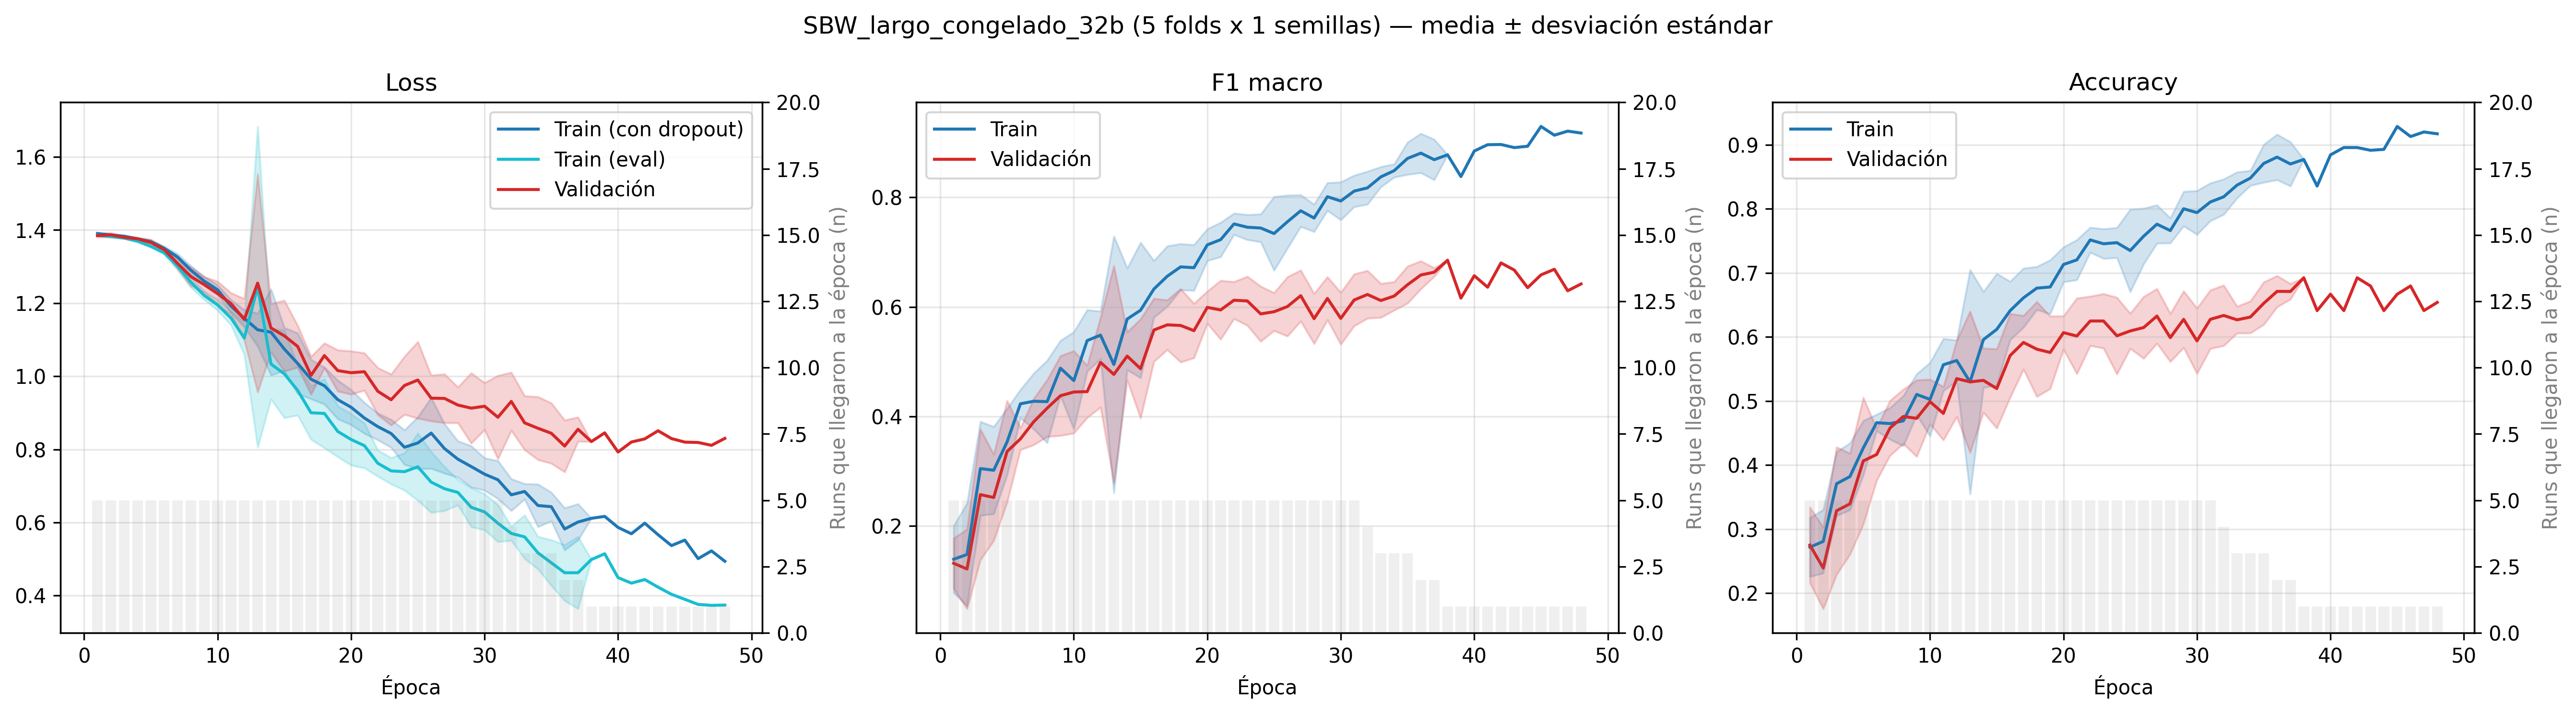

SBW_largo_lr2e-3_congelado_32b


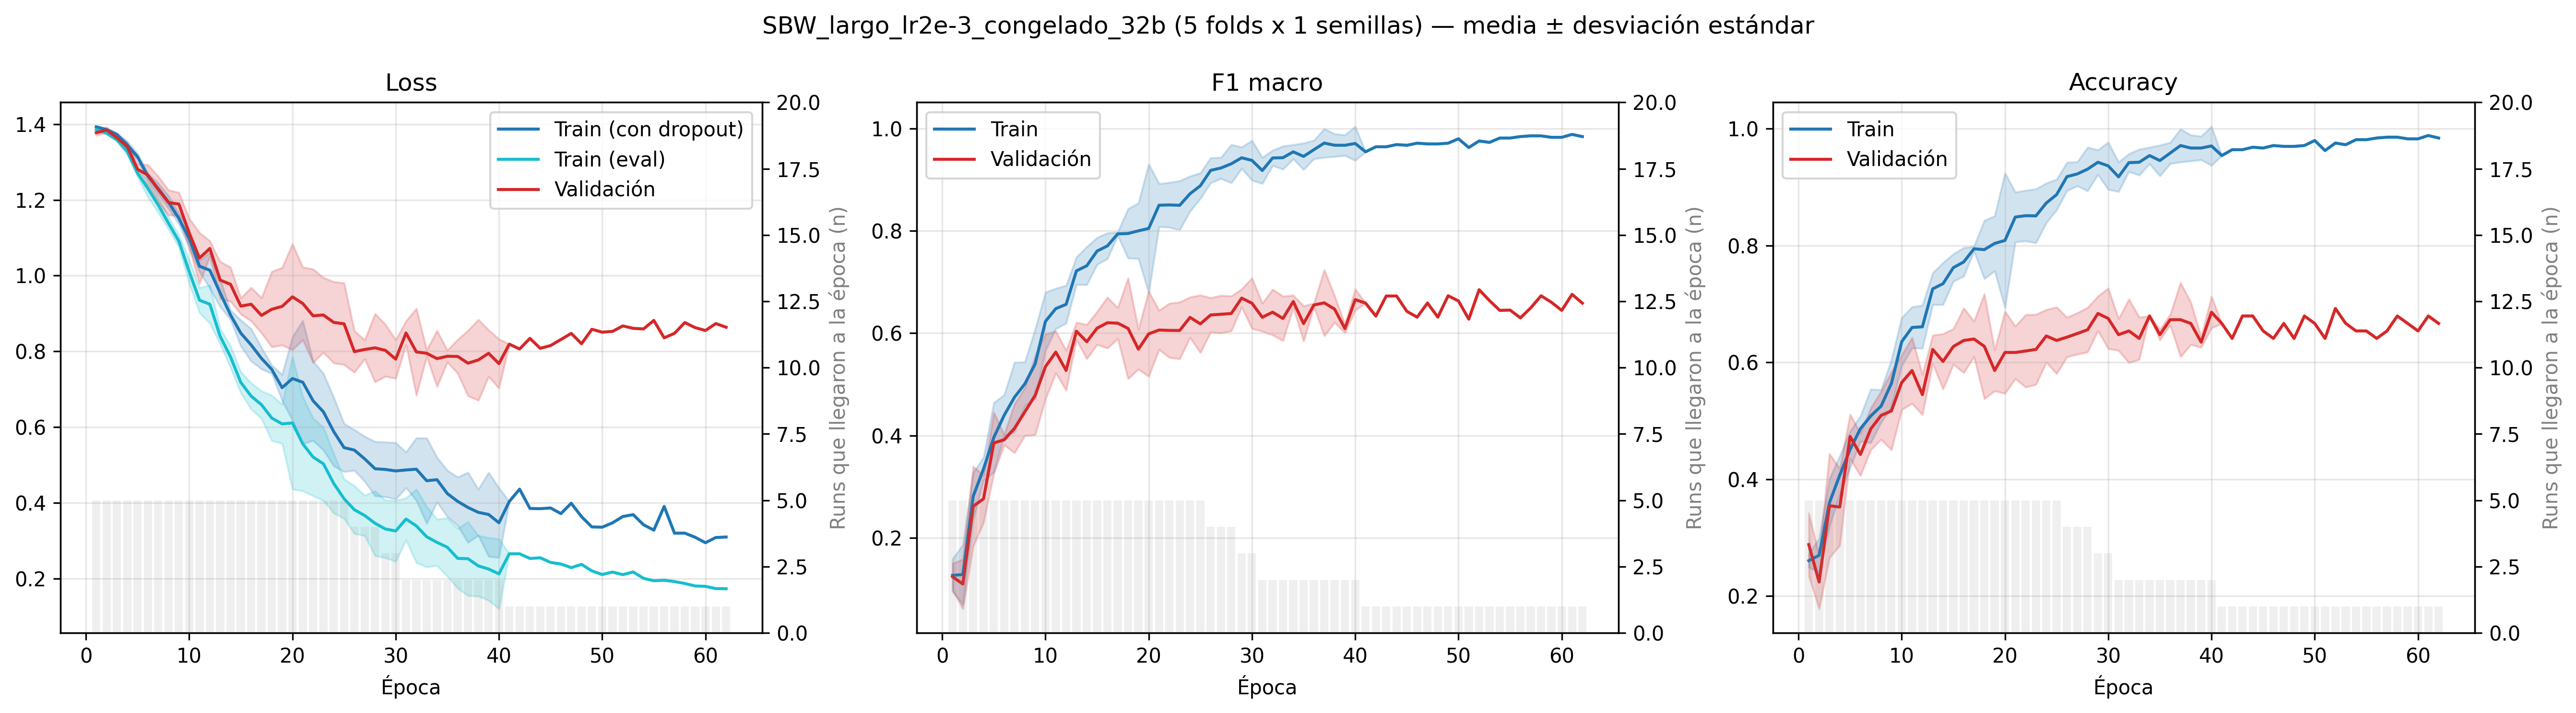

SBW_largo_ajustado-ep10_32b


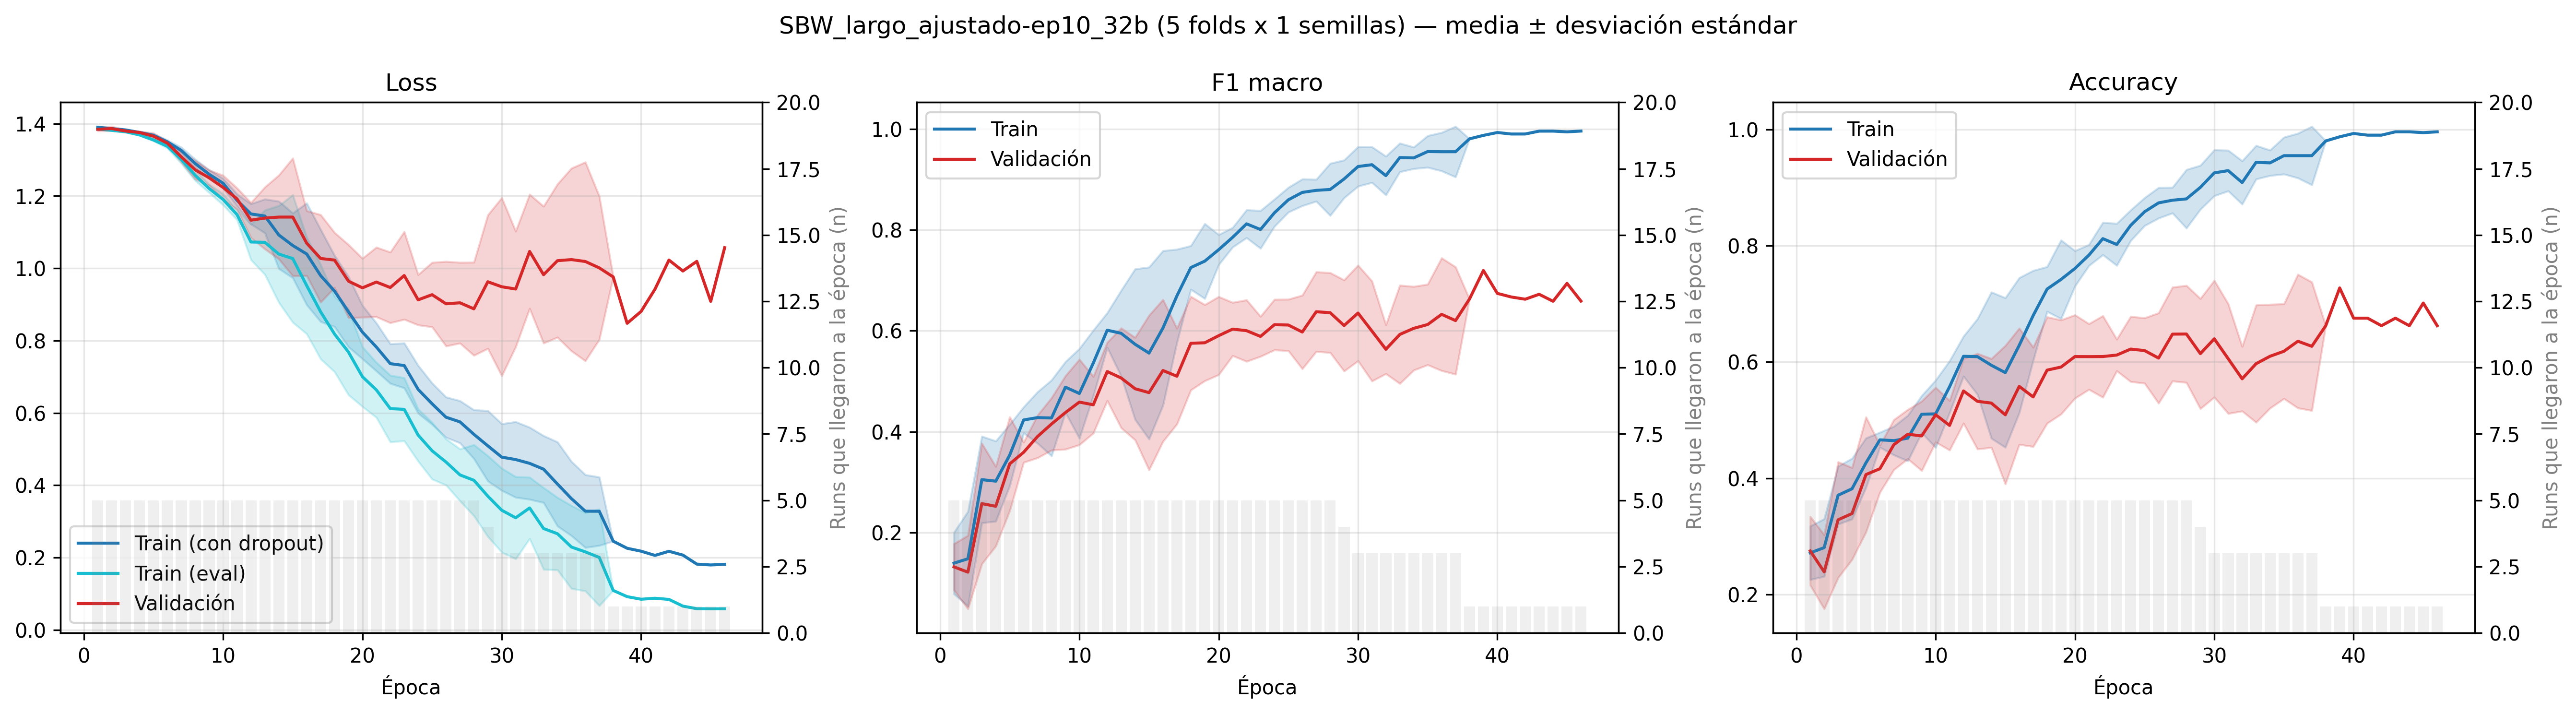

In [36]:
# Resumen de esta corrida
from IPython.display import display, Image
if os.path.exists(ruta_global):
    rg = pd.read_csv(ruta_global)
    display(rg[["experimento", "tipo", "modelo", "datos_test", "n_corridas", "f1_macro_mean", "f1_macro_std",
                "accuracy_mean"]].round(4))
for cfg in EXPERIMENTOS:
    d = os.path.join(dir_corrida, cfg.nombre_experimento, "viewers")
    if os.path.exists(os.path.join(d, "curvas_medias.png")):
        print(cfg.nombre_experimento)
        display(Image(os.path.join(d, "curvas_medias.png"), width=1100))

## 11. Consolidar corridas (sesiones en paralelo)
Cuando terminen todas las sesiones, pon aquí las carpetas de sus corridas para obtener un solo resumen y la comparativa individual vs pool.

In [39]:
# Ejemplo: junta las corridas de varias sesiones (y, si las copiaste a Drive, las de tu equipo)
DIR_SALIDAS = os.path.join(RAIZ, "data/output/bilstm_cv")
CORRIDAS = [
    os.path.join(DIR_SALIDAS, "corrida_2026-11-03_06-19-05_03-11-2026_06-18-36"),
    os.path.join(DIR_SALIDAS, "corrida_2026-11-03_06-17-20_03-11-2026_06-17-10"),
    os.path.join(DIR_SALIDAS, "corrida_2026-11-03_06-17-19_03-11-2026_06-17-10"),
    os.path.join(DIR_SALIDAS, "corrida_2026-11-03_06-17-08_03-11-2026_06-16-59"),
]
if CORRIDAS:
    rg, comp = consolidar_corridas(CORRIDAS, os.path.join(DIR_SALIDAS, "consolidado"))
    display(rg[["experimento", "corrida", "tipo", "modelo", "datos_test", "f1_macro_mean", "f1_macro_std"]].round(4))
    if comp is not None and not comp.empty:
        display(comp.round(4))

Consolidado en /content/drive/MyDrive/FuncionesPLN/data/output/bilstm_cv/consolidado: 3 experimentos


,experimento,corrida,tipo,modelo,datos_test,f1_macro_mean,f1_macro_std
0,SBW_largo_ajustado-ep10_32b,corrida_2026-11-03_06-19-05_03-11-2026_06-18-36,individual,bilstm,32b,0.6045,0.0280
1,SBW_largo_ajustado-ep10_32b,corrida_2026-11-03_06-19-05_03-11-2026_06-18-36,individual,promedio_emb_lr,32b,0.3307,0.0363
2,SBW_largo_ajustado-ep10_32b,corrida_2026-11-03_06-19-05_03-11-2026_06-18-36,individual,tfidf_lr,32b,0.5485,0.0524
3,SBW_largo_congelado_32b,corrida_2026-11-03_06-19-05_03-11-2026_06-18-36,individual,bilstm,32b,0.6198,0.0323
4,SBW_largo_congelado_32b,corrida_2026-11-03_06-19-05_03-11-2026_06-18-36,individual,promedio_emb_lr,32b,0.3307,0.0363
5,SBW_largo_congelado_32b,corrida_2026-11-03_06-19-05_03-11-2026_06-18-36,individual,tfidf_lr,32b,0.5485,0.0524
6,SBW_largo_lr2e-3_congelado_32b,corrida_2026-11-03_06-19-05_03-11-2026_06-18-36,individual,bilstm,32b,0.6260,0.0253
7,SBW_largo_lr2e-3_congelado_32b,corrida_2026-11-03_06-19-05_03-11-2026_06-18-36,individual,promedio_emb_lr,32b,0.3307,0.0363
8,SBW_largo_lr2e-3_congelado_32b,corrida_2026-11-03_06-19-05_03-11-2026_06-18-36,individual,tfidf_lr,32b,0.5485,0.0524
